# Project 2 — Mathematical Network Analysis Using Graph Theory

### Case studies: Zachary's Karate Club (34 nodes) and the American college football network (115 nodes)

**Problem.** Social networks, communication systems and organisational structures contain complex
relationships. Build a system that (a) **represents** such a network mathematically, (b) **finds the
important nodes**, (c) **detects communities**, and (d) **quantifies how the network falls apart**
when those nodes are removed.

**Ground rule of this notebook:** every data structure and algorithm is implemented **from scratch**
with plain Python + NumPy. NetworkX appears only once, in the verification section, as an independent
referee — never to do the actual work.

| | |
|---|---|
| **Networks** | Karate club, 34 nodes / 78 edges (1977); college football, 115 nodes / 613 games |
| **Data** | Both edge lists embedded — no downloads, runs offline in Colab |
| **Math** | graph theory, combinatorics, probability (random walks), linear algebra (spectra) |
| **DSA** | adjacency list, hash maps, BFS/DFS, union-find, priority queue, Brandes' algorithm |
| **ML** | spectral embedding + k-means++ clustering |
| **Runtime** | under one minute on a free Colab CPU |

> **How to run:** `Runtime → Run all`. Nothing to install. Figures are written to `figures/`.

---

## 1. Problem statement

Social networks, communication systems, and organisational structures contain complex relationships.
The task is to develop a **mathematical network analysis system** that identifies **important nodes**,
**communities**, and **relationships** inside large networks.

By the end of this notebook we can answer:

1. Which members are the most **connected**, the best **connected to everyone**, and which ones sit on
   the **shortest paths between others**? *(degree, closeness, betweenness)*
2. Which members are **influential** in the sense of a random walk through the network? *(PageRank)*
3. Does the club **split into communities**, and do those communities match the historical split?
   *(Girvan–Newman, spectral clustering)*
4. What happens to the network if the top nodes are **removed**? *(robustness experiment)*
5. Do the conclusions **generalise** to a second, larger network with a different density and a known
   12-conference ground truth? *(cross-dataset comparison)*

## 2. Mathematical and DSA concepts used

| Concept | Where it appears in this notebook |
|---|---|
| **Graph theory** | $G=(V,E)$, adjacency, paths, connected components, diameter |
| **Combinatorics** | counting node pairs and shortest paths $\sigma_{st}$ |
| **Probability** | random-surfer Markov chain behind PageRank |
| **Linear algebra** | adjacency / Laplacian matrices, eigenvalues, eigenvectors |
| **Network analysis** | centrality, modularity, community structure |
| **Graph connectivity** | components, algebraic connectivity, fragmentation under attack |
| **Graph** | adjacency list: `dict[node, dict[neighbour, weight]]` |
| **BFS / DFS** | shortest paths, traversal order, components |
| **Union-Find** | dynamic connectivity with path compression |
| **Hash maps** | node attributes, distance/parent tables, algorithm state |
| **Priority queue** | ranking the most influential nodes (heap) |
| **Clustering (AI/ML)** | spectral embedding + k-means to discover groups |

## 3. Pipeline

```
  raw edge list (karate, football)
       |
       v
  Graph object  --->  BFS / DFS / Union-Find  --->  connectivity, distances
       |
       +----------->  degree / closeness / betweenness / PageRank  --->  node ranking
       |
       +----------->  Girvan-Newman + spectral k-means  ----------->  communities
       |
       +----------->  node-removal simulation  --------------------->  robustness
       |
       +----------->  repeat on the second network  ---------------->  generalisation
```

Everything below is organised in that order.

## 4. Setup

Only the scientific-Python stack that Colab already ships with is used. `networkx` is optional and
only imported for the verification section.

In [25]:
%matplotlib inline

import math, heapq, random, time, os
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

os.makedirs("figures", exist_ok=True)

def savefig(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"saved -> {path}")

print("Environment ready.")

Environment ready.


## 5. Representing the network

The graph is stored as an **adjacency list**: a hash map from a node to a hash map of its neighbours
(and edge weights). For a sparse social network this is far better than a dense matrix:

* neighbour lookup — $O(1)$ average
* iterate over a node's edges — $O(\deg(v))$ instead of $O(V)$
* memory — $O(V+E)$ instead of $O(V^2)$

The adjacency **matrix** is still built on demand, because linear algebra (PageRank, spectra) is much
easier in matrix form.

### 5.1 The first dataset: Zachary's karate club

Zachary (1977) observed a university karate club for two years. A conflict between the instructor
("Mr. Hi", node 0) and the administrator ("Officer", node 33) split the club in two. The 78 friendship
edges and the final faction of every member are the ground truth we will try to recover.

In [26]:
class Graph:
    """Undirected, unweighted simple graph.

    adj  : dict[node, dict[neighbour, weight]]  -> O(1) neighbour lookup
    meta : dict[node, dict]                     -> free-form node attributes
    """
    def __init__(self, n=0, directed=False):
        self.directed = directed
        self.adj = {u: {} for u in range(n)}
        self.meta = {}

    # ---------------- construction ----------------
    def add_node(self, u, **attrs):
        self.adj.setdefault(u, {})
        self.meta.setdefault(u, {}).update(attrs)

    def add_edge(self, u, v, w=1.0):
        if u == v:
            raise ValueError("self-loops are not supported")
        self.add_node(u)
        self.add_node(v)
        self.adj[u][v] = w
        if not self.directed:
            self.adj[v][u] = w

    def remove_edge(self, u, v):
        self.adj[u].pop(v, None)
        if not self.directed:
            self.adj[v].pop(u, None)

    def remove_node(self, u):
        for v in list(self.adj[u]):
            self.adj[v].pop(u, None)
        del self.adj[u]
        self.meta.pop(u, None)

    def copy(self):
        h = Graph(0, self.directed)
        h.adj = {u: dict(nb) for u, nb in self.adj.items()}
        h.meta = {u: dict(a) for u, a in self.meta.items()}
        return h

    # ---------------- queries ----------------
    def nodes(self):
        return list(self.adj)

    def neighbors(self, u):
        return self.adj[u].keys()

    def degree(self, u):
        return len(self.adj[u])

    def __len__(self):
        return len(self.adj)

    def edge_list(self):
        if self.directed:
            return [(u, v) for u in self.adj for v in self.adj[u]]
        seen, out = set(), []
        for u in self.adj:
            for v in self.adj[u]:
                e = (u, v) if u < v else (v, u)
                if e not in seen:
                    seen.add(e)
                    out.append(e)
        return out

    def number_of_edges(self):
        s = sum(len(nb) for nb in self.adj.values())
        return s if self.directed else s // 2

    def density(self):
        n, m = len(self), self.number_of_edges()
        return m / (n * (n - 1) / 2) if n > 1 else 0.0

    # ---------------- matrix views ----------------
    def adjacency_matrix(self, order=None):
        order = list(self.adj) if order is None else list(order)
        idx = {u: i for i, u in enumerate(order)}
        A = np.zeros((len(order), len(order)))
        for u in order:
            for v, w in self.adj[u].items():
                if v in idx:
                    A[idx[u], idx[v]] = w
        return A

    def laplacian_matrix(self, normalized=False):
        A = self.adjacency_matrix()
        d = A.sum(axis=1)
        if not normalized:
            return np.diag(d) - A
        inv = np.divide(1.0, np.sqrt(d), out=np.zeros_like(d), where=d > 0)
        return np.eye(len(d)) - inv[:, None] * A * inv[None, :]

    def __repr__(self):
        return f"Graph(n={len(self)}, m={self.number_of_edges()}, directed={self.directed})"


# Zachary's Karate Club: 78 undirected edges, 0-indexed (standard ordering)
EDGES = [
    (0,1),(0,2),(0,3),(0,4),(0,5),(0,6),(0,7),(0,8),(0,10),(0,11),(0,12),(0,13),
    (0,17),(0,19),(0,21),(0,31),
    (1,2),(1,3),(1,7),(1,13),(1,17),(1,19),(1,21),(1,30),
    (2,3),(2,7),(2,8),(2,9),(2,13),(2,27),(2,28),(2,32),
    (3,7),(3,12),(3,13),
    (4,6),(4,10),
    (5,6),(5,10),(5,16),
    (6,16),
    (8,30),(8,32),(8,33),
    (9,33),
    (13,33),
    (14,32),(14,33),
    (15,32),(15,33),
    (18,32),(18,33),
    (19,33),
    (20,32),(20,33),
    (22,32),(22,33),
    (23,25),(23,27),(23,29),(23,32),(23,33),
    (24,25),(24,27),(24,31),
    (25,31),
    (26,29),(26,33),
    (27,33),
    (28,31),(28,33),
    (29,32),(29,33),
    (30,32),(30,33),
    (31,32),(31,33),
    (32,33),
]

# Ground truth after the split: 0 = Mr. Hi's faction, 1 = Officer's faction
FACTION = [0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1]

G = Graph(34)
for u, v in EDGES:
    G.add_edge(u, v)
for u in G.nodes():
    G.meta[u] = {"faction": "Mr. Hi" if FACTION[u] == 0 else "Officer", "id": u}

assert len(G) == 34 and G.number_of_edges() == 78
print(G)
print(f"Average degree : {2 * G.number_of_edges() / len(G):.2f}")
print(f"Density        : {G.density():.3f}")
print(f"Faction sizes  : Mr. Hi = {FACTION.count(0)}, Officer = {FACTION.count(1)}")

Graph(n=34, m=78, directed=False)
Average degree : 4.59
Density        : 0.139
Faction sizes  : Mr. Hi = 16, Officer = 18


### The matrix view and the degree distribution

The symmetric matrix $A$ has $A_{ij}=1$ exactly when $i$ and $j$ are friends. Its row sums are the
degrees $k_i$, and the degree sequence already tells us that this is a **right-skewed** network: a few
members have many ties, most have only one or two.

saved -> figures\01_adjacency_and_degrees.png


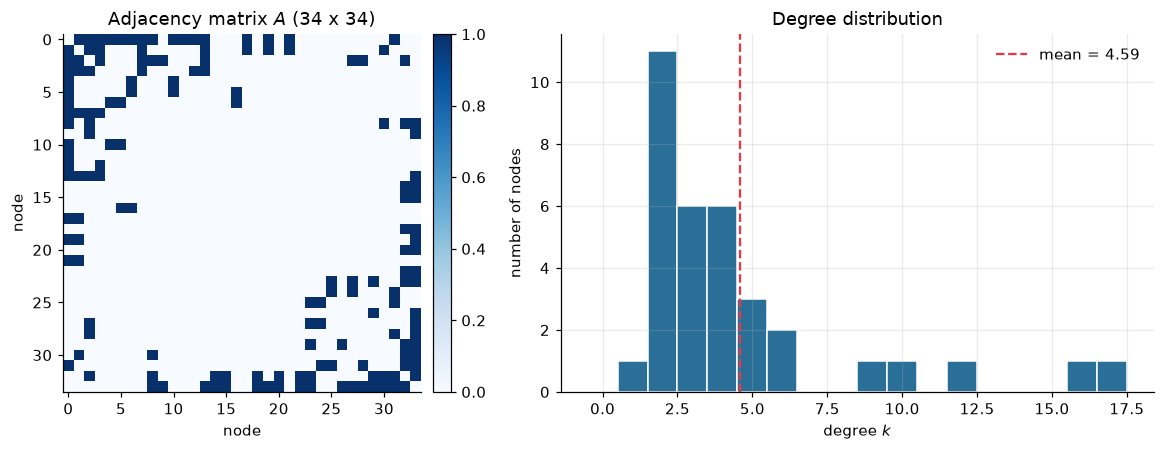

Degree sequence (sorted): [np.int64(17), np.int64(16), np.int64(12), np.int64(10), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(5), np.int64(5), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(4), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(1)]
Top-5 hubs: [33, 0, 32, 2, 1]


In [27]:
A = G.adjacency_matrix()
deg_raw = np.array([G.degree(u) for u in G.nodes()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
im = axes[0].imshow(A, cmap="Blues", interpolation="nearest")
axes[0].set_title("Adjacency matrix $A$ (34 x 34)")
axes[0].set_xlabel("node")
axes[0].set_ylabel("node")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.02)

axes[1].hist(deg_raw, bins=range(0, deg_raw.max() + 2), color="#2a6f97",
             edgecolor="white", align="left")
axes[1].set_title("Degree distribution")
axes[1].set_xlabel("degree $k$")
axes[1].set_ylabel("number of nodes")
axes[1].axvline(deg_raw.mean(), color="#e63946", ls="--",
                label=f"mean = {deg_raw.mean():.2f}")
axes[1].legend(frameon=False)
fig.tight_layout()
savefig(fig, "01_adjacency_and_degrees.png")
plt.show()

print("Degree sequence (sorted):", sorted(deg_raw, reverse=True))
print("Top-5 hubs:", sorted(G.nodes(), key=G.degree, reverse=True)[:5])

### 5.2 A second dataset: the American college football network

To test whether the findings **generalise**, the same pipeline is repeated on a larger, denser network:
115 US college football teams, 613 games, and 12 conferences (Girvan & Newman, 2002; Newman's network
data). Two teams are linked when they played each other in the 2000 season. Conference membership is the known
ground truth, used only for evaluation — never as an input to any algorithm.

The network is embedded below in exactly the same adjacency-list representation as the karate club, so
the notebook still runs offline with no downloads.

In [28]:
# American college football network: 115 teams, 613 games, 12 conferences.
# Conference id (0..11) is the ground-truth label used later for ARI.

FOOTBALL_NAMES = ['BrighamYoung', 'FloridaState', 'Iowa', 'KansasState', 'NewMexico', 'TexasTech', 'PennState', 'SouthernCalifornia', 'ArizonaState', 'SanDiegoState', 'Baylor', 'NorthTexas', 'NorthernIllinois', 'Northwestern', 'WesternMichigan', 'Wisconsin', 'Wyoming', 'Auburn', 'Akron', 'VirginiaTech', 'Alabama', 'UCLA', 'Arizona', 'Utah', 'ArkansasState', 'NorthCarolinaState', 'BallState', 'Florida', 'BoiseState', 'BostonCollege', 'WestVirginia', 'BowlingGreenState', 'Michigan', 'Virginia', 'Buffalo', 'Syracuse', 'CentralFlorida', 'GeorgiaTech', 'CentralMichigan', 'Purdue', 'Colorado', 'ColoradoState', 'Connecticut', 'EasternMichigan', 'EastCarolina', 'Duke', 'FresnoState', 'OhioState', 'Houston', 'Rice', 'Idaho', 'Washington', 'Kansas', 'SouthernMethodist', 'Kent', 'Pittsburgh', 'Kentucky', 'Louisville', 'LouisianaTech', 'LouisianaMonroe', 'Minnesota', 'MiamiOhio', 'Vanderbilt', 'MiddleTennesseeState', 'Illinois', 'MississippiState', 'Memphis', 'Nevada', 'Oregon', 'NewMexicoState', 'SouthCarolina', 'Ohio', 'IowaState', 'SanJoseState', 'Nebraska', 'SouthernMississippi', 'Tennessee', 'Stanford', 'WashingtonState', 'Temple', 'Navy', 'TexasA&M', 'NotreDame', 'TexasElPaso', 'Oklahoma', 'Toledo', 'Tulane', 'Mississippi', 'Tulsa', 'NorthCarolina', 'UtahState', 'Army', 'Cincinnati', 'AirForce', 'Rutgers', 'Georgia', 'LouisianaState', 'LouisianaLafayette', 'Texas', 'Marshall', 'MichiganState', 'MiamiFlorida', 'Missouri', 'Clemson', 'NevadaLasVegas', 'WakeForest', 'Indiana', 'OklahomaState', 'OregonState', 'Maryland', 'TexasChristian', 'California', 'AlabamaBirmingham', 'Arkansas', 'Hawaii']

FOOTBALL_CONF = [7, 0, 2, 3, 7, 3, 2, 8, 8, 7, 3, 10, 6, 2, 6, 2, 7, 9, 6, 1, 9, 8, 8, 7, 10, 0, 6, 9, 11, 1, 1, 6, 2, 0, 6, 1, 5, 0, 6, 2, 3, 7, 5, 6, 4, 0, 11, 2, 4, 11, 10, 8, 3, 11, 6, 1, 9, 4, 11, 10, 2, 6, 9, 10, 2, 9, 4, 11, 8, 10, 9, 6, 3, 11, 3, 4, 9, 8, 8, 1, 5, 3, 5, 11, 3, 6, 4, 9, 11, 0, 5, 4, 4, 7, 1, 9, 9, 10, 3, 6, 2, 1, 3, 0, 7, 0, 2, 3, 8, 0, 4, 8, 4, 9, 11]

FOOTBALL_EDGES = [
    (0, 1), (0, 4), (0, 9), (0, 16), (0, 23), (0, 33), (0, 35), (0, 41),
    (0, 65), (0, 90), (0, 93), (0, 104), (1, 25), (1, 27), (1, 33), (1, 37),
    (1, 45), (1, 57), (1, 89), (1, 101), (1, 103), (1, 105), (1, 109), (2, 3),
    (2, 6), (2, 13), (2, 14), (2, 15), (2, 47), (2, 60), (2, 64), (2, 72),
    (2, 74), (2, 100), (2, 106), (3, 5), (3, 11), (3, 26), (3, 40), (3, 52),
    (3, 58), (3, 72), (3, 74), (3, 81), (3, 84), (3, 102), (4, 5), (4, 9),
    (4, 16), (4, 23), (4, 28), (4, 41), (4, 69), (4, 93), (4, 104), (4, 108),
    (5, 10), (5, 11), (5, 52), (5, 74), (5, 81), (5, 84), (5, 90), (5, 97),
    (5, 98), (5, 107), (6, 7), (6, 32), (6, 39), (6, 47), (6, 55), (6, 58),
    (6, 60), (6, 64), (6, 85), (6, 100), (6, 106), (7, 8), (7, 21), (7, 22),
    (7, 40), (7, 68), (7, 73), (7, 77), (7, 78), (7, 82), (7, 108), (7, 111),
    (8, 9), (8, 21), (8, 22), (8, 41), (8, 51), (8, 68), (8, 77), (8, 78),
    (8, 90), (8, 111), (9, 16), (9, 22), (9, 23), (9, 41), (9, 64), (9, 93),
    (9, 104), (9, 108), (10, 11), (10, 60), (10, 72), (10, 74), (10, 81), (10, 84),
    (10, 98), (10, 102), (10, 107), (11, 24), (11, 28), (11, 50), (11, 69), (11, 90),
    (11, 97), (11, 104), (12, 13), (12, 14), (12, 17), (12, 18), (12, 26), (12, 34),
    (12, 36), (12, 38), (12, 43), (12, 85), (13, 15), (13, 32), (13, 39), (13, 45),
    (13, 60), (13, 64), (13, 100), (13, 106), (13, 110), (14, 15), (14, 26), (14, 38),
    (14, 43), (14, 54), (14, 71), (14, 85), (14, 99), (15, 32), (15, 39), (15, 47),
    (15, 60), (15, 68), (15, 92), (15, 100), (15, 106), (15, 114), (16, 17), (16, 23),
    (16, 38), (16, 41), (16, 67), (16, 81), (16, 93), (16, 104), (17, 20), (17, 27),
    (17, 58), (17, 62), (17, 65), (17, 87), (17, 95), (17, 96), (17, 113), (18, 19),
    (18, 31), (18, 34), (18, 36), (18, 38), (18, 42), (18, 54), (18, 61), (18, 71),
    (18, 99), (19, 29), (19, 30), (19, 33), (19, 35), (19, 36), (19, 44), (19, 55),
    (19, 79), (19, 94), (19, 101), (20, 21), (20, 36), (20, 62), (20, 65), (20, 70),
    (20, 75), (20, 76), (20, 87), (20, 96), (20, 113), (21, 22), (21, 32), (21, 46),
    (21, 51), (21, 68), (21, 77), (21, 108), (21, 111), (22, 23), (22, 47), (22, 51),
    (22, 68), (22, 77), (22, 78), (22, 108), (23, 41), (23, 78), (23, 90), (23, 93),
    (23, 104), (23, 111), (24, 25), (24, 28), (24, 50), (24, 66), (24, 69), (24, 84),
    (24, 87), (24, 90), (24, 110), (25, 33), (25, 37), (25, 45), (25, 53), (25, 89),
    (25, 103), (25, 105), (25, 106), (25, 109), (26, 27), (26, 34), (26, 38), (26, 42),
    (26, 43), (26, 61), (26, 85), (27, 56), (27, 62), (27, 63), (27, 65), (27, 70),
    (27, 76), (27, 95), (27, 96), (28, 38), (28, 50), (28, 69), (28, 78), (28, 90),
    (28, 113), (29, 30), (29, 35), (29, 42), (29, 55), (29, 79), (29, 80), (29, 82),
    (29, 91), (29, 94), (29, 101), (30, 35), (30, 44), (30, 50), (30, 55), (30, 79),
    (30, 82), (30, 94), (30, 101), (30, 109), (31, 32), (31, 34), (31, 43), (31, 54),
    (31, 55), (31, 61), (31, 71), (31, 79), (31, 85), (31, 99), (32, 39), (32, 47),
    (32, 49), (32, 64), (32, 100), (32, 106), (33, 37), (33, 45), (33, 89), (33, 103),
    (33, 105), (33, 109), (34, 35), (34, 42), (34, 54), (34, 61), (34, 71), (34, 94),
    (34, 99), (35, 44), (35, 55), (35, 79), (35, 92), (35, 94), (35, 101), (36, 37),
    (36, 43), (36, 58), (36, 59), (37, 45), (37, 80), (37, 89), (37, 95), (37, 103),
    (37, 105), (37, 109), (38, 39), (38, 43), (38, 54), (38, 71), (38, 85), (39, 47),
    (39, 54), (39, 60), (39, 82), (39, 100), (39, 106), (40, 41), (40, 51), (40, 52),
    (40, 72), (40, 74), (40, 81), (40, 98), (40, 102), (40, 107), (41, 67), (41, 93),
    (41, 104), (42, 43), (42, 57), (42, 63), (43, 61), (43, 70), (43, 79), (43, 85),
    (44, 45), (44, 48), (44, 57), (44, 66), (44, 75), (44, 86), (44, 91), (44, 112),
    (45, 62), (45, 89), (45, 103), (45, 105), (45, 109), (46, 47), (46, 49), (46, 53),
    (46, 67), (46, 73), (46, 83), (46, 88), (46, 110), (46, 111), (46, 114), (47, 60),
    (47, 61), (47, 64), (47, 100), (48, 49), (48, 53), (48, 57), (48, 66), (48, 75),
    (48, 86), (48, 91), (48, 92), (48, 96), (48, 98), (49, 53), (49, 67), (49, 73),
    (49, 83), (49, 84), (49, 88), (49, 110), (49, 114), (50, 51), (50, 68), (50, 69),
    (50, 78), (50, 90), (51, 68), (51, 77), (51, 78), (51, 101), (51, 108), (51, 111),
    (52, 53), (52, 72), (52, 74), (52, 84), (52, 98), (52, 102), (52, 112), (53, 67),
    (53, 73), (53, 83), (53, 86), (53, 88), (53, 110), (53, 114), (54, 55), (54, 61),
    (54, 71), (54, 99), (55, 79), (55, 89), (55, 94), (55, 101), (56, 57), (56, 62),
    (56, 65), (56, 70), (56, 76), (56, 87), (56, 95), (56, 96), (56, 106), (57, 75),
    (57, 86), (57, 91), (57, 92), (57, 112), (58, 59), (58, 63), (58, 88), (58, 97),
    (58, 101), (58, 114), (59, 60), (59, 63), (59, 66), (59, 76), (59, 97), (59, 113),
    (60, 64), (60, 71), (60, 106), (61, 62), (61, 71), (61, 92), (61, 99), (62, 70),
    (62, 76), (62, 87), (62, 95), (62, 105), (63, 64), (63, 65), (63, 97), (63, 109),
    (63, 112), (64, 100), (64, 106), (64, 111), (65, 66), (65, 70), (65, 87), (65, 96),
    (65, 113), (66, 75), (66, 76), (66, 86), (66, 91), (66, 92), (66, 112), (67, 68),
    (67, 73), (67, 83), (67, 88), (67, 104), (67, 110), (67, 114), (68, 78), (68, 108),
    (68, 111), (69, 70), (69, 83), (69, 88), (69, 90), (69, 91), (69, 95), (70, 76),
    (70, 95), (70, 103), (70, 113), (71, 72), (71, 99), (72, 74), (72, 81), (72, 102),
    (72, 104), (72, 107), (73, 74), (73, 77), (73, 83), (73, 88), (73, 110), (73, 114),
    (74, 82), (74, 84), (74, 102), (75, 76), (75, 86), (75, 92), (75, 107), (75, 112),
    (76, 95), (76, 96), (76, 113), (77, 78), (77, 82), (77, 98), (77, 108), (77, 111),
    (78, 108), (78, 111), (79, 80), (79, 94), (79, 101), (79, 109), (80, 82), (80, 85),
    (80, 86), (80, 91), (80, 93), (80, 94), (80, 105), (80, 110), (81, 82), (81, 83),
    (81, 84), (81, 98), (81, 107), (82, 93), (82, 94), (82, 100), (83, 84), (83, 88),
    (83, 110), (83, 114), (84, 98), (84, 107), (85, 99), (86, 87), (86, 91), (86, 92),
    (86, 97), (87, 95), (87, 96), (87, 104), (87, 113), (88, 89), (88, 107), (88, 110),
    (88, 114), (89, 99), (89, 103), (89, 105), (89, 109), (91, 92), (91, 93), (91, 112),
    (92, 106), (92, 112), (93, 104), (94, 101), (95, 113), (96, 112), (96, 113), (97, 98),
    (97, 112), (98, 102), (98, 107), (99, 100), (100, 102), (102, 103), (102, 107), (103, 105),
    (103, 109), (104, 114), (105, 109), (108, 111), (110, 114),
]

FB = Graph(len(FOOTBALL_NAMES))
for u, v in FOOTBALL_EDGES:
    FB.add_edge(u, v)
for u in FB.nodes():
    FB.meta[u] = {"name": FOOTBALL_NAMES[u], "conference": FOOTBALL_CONF[u], "id": u}

assert len(FB) == 115 and FB.number_of_edges() == 613
print(FB)
print(f"Average degree : {2 * FB.number_of_edges() / len(FB):.2f}")
print(f"Density        : {FB.density():.4f}")
print(f"Conferences    : {len(set(FOOTBALL_CONF))} "
      f"(sizes {[FOOTBALL_CONF.count(c) for c in range(12)]})")

Graph(n=115, m=613, directed=False)
Average degree : 10.66
Density        : 0.0935
Conferences    : 12 (sizes [9, 8, 11, 12, 10, 5, 13, 8, 10, 12, 7, 10])


## 6. Traversal: BFS, DFS, connectivity, Union-Find

Both traversals are $O(V+E)$; the only difference is the container:

| Traversal | Container | Gives us |
|---|---|---|
| **BFS** | queue (FIFO) | shortest path lengths in an unweighted graph, layers |
| **DFS** | stack (LIFO) | a deep traversal order, cycle / back-edge detection |

**Connected components** can be produced three ways, which is a nice consistency check:

1. repeatedly run BFS from an unvisited node — $O(V+E)$;
2. **Union-Find** over the edge list — $O(E\,\alpha(V))$ with path compression + union by size;
3. DFS — same complexity as BFS.

Union-Find matters in practice because it also supports *dynamic* connectivity: adding edges and
asking "same component?" in near-constant time.

In [29]:
def bfs(g, s):
    """Breadth-first search from s -> (visit order, distances, parents)."""
    dist = {u: -1 for u in g.nodes()}
    parent = {u: None for u in g.nodes()}
    dist[s] = 0
    order = []
    q = deque([s])
    while q:
        u = q.popleft()
        order.append(u)
        for v in g.neighbors(u):
            if dist[v] == -1:          # first time we see v => shortest path found
                dist[v] = dist[u] + 1
                parent[v] = u
                q.append(v)
    return order, dist, parent


def dfs(g, s):
    """Iterative depth-first search (pre-order)."""
    visited, order, parent = set(), [], {s: None}
    stack = [s]
    while stack:
        u = stack.pop()
        if u in visited:
            continue
        visited.add(u)
        order.append(u)
        for v in reversed(list(g.neighbors(u))):
            if v not in visited:
                parent.setdefault(v, u)
                stack.append(v)
    return order, parent


def shortest_path(g, s, t):
    _, dist, parent = bfs(g, s)
    if dist[t] == -1:
        return None
    path, cur = [], t
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    return path[::-1]


def connected_components(g):
    """Components via repeated BFS: O(V + E) overall."""
    seen, comps = set(), []
    for u in g.nodes():
        if u not in seen:
            order, _, _ = bfs(g, u)
            seen.update(order)
            comps.append(order)
    return sorted(comps, key=len, reverse=True)


class UnionFind:
    """Disjoint-set forest with union by size and path compression."""
    def __init__(self, nodes):
        self.parent = {u: u for u in nodes}
        self.size = {u: 1 for u in nodes}
        self.count = len(self.parent)

    def find(self, u):
        root = u
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[u] != root:          # path compression
            self.parent[u], u = root, self.parent[u]
        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.size[ra] < self.size[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        self.size[ra] += self.size[rb]
        self.count -= 1
        return True


order, dist, parent = bfs(G, 0)
print("BFS from node 0 :", order)
print("BFS distances   :", [dist[u] for u in G.nodes()])
print("DFS pre-order   :", dfs(G, 0)[0])
print("Shortest 0 -> 33:", shortest_path(G, 0, 33))

comps = connected_components(G)
print(f"Components (BFS): {len(comps)} -> sizes {[len(c) for c in comps]}")

uf = UnionFind(G.nodes())
merges = sum(uf.union(u, v) for u, v in G.edge_list())
print(f"Union-Find      : {merges} successful unions -> {uf.count} component(s)")

diam = max(d for u in G.nodes() for d in bfs(G, u)[1].values() if d >= 0)
avg_path = np.mean([d for u in G.nodes() for d in bfs(G, u)[1].values() if d > 0])
print(f"Diameter        : {diam}")
print(f"Avg. path length: {avg_path:.3f}")

BFS from node 0 : [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31, 30, 9, 27, 28, 32, 16, 33, 24, 25, 23, 14, 15, 18, 20, 22, 29, 26]
BFS distances   : [0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 3, 3, 2, 1, 3, 1, 3, 1, 3, 3, 2, 2, 3, 2, 2, 3, 2, 1, 2, 2]
DFS pre-order   : [0, 1, 2, 3, 7, 12, 13, 33, 8, 30, 32, 14, 15, 18, 20, 22, 23, 25, 24, 27, 31, 28, 29, 26, 9, 19, 17, 21, 4, 6, 5, 10, 16, 11]
Shortest 0 -> 33: [0, 8, 33]
Components (BFS): 1 -> sizes [34]
Union-Find      : 33 successful unions -> 1 component(s)
Diameter        : 5
Avg. path length: 2.408


## 7. Centrality: who matters?

Three complementary definitions of "important", each with a different mathematical idea.

**Degree centrality** — pure combinatorics; count the neighbours and normalise by the maximum $n-1$.

$$C_D(v) = \frac{\deg(v)}{n-1}$$

**Closeness centrality** — how fast information reaches everybody; the reciprocal of the mean
shortest-path distance (computed with one BFS per node).

$$C_C(v) = \frac{n-1}{\sum_{u \neq v} d(v,u)}$$

**Betweenness centrality** — how much a node acts as a **bridge**. For every ordered pair $(s,t)$,
count the fraction of shortest paths that pass through $v$, then sum:

$$C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

Computing this naively costs $O(V^3)$; **Brandes' algorithm** does it in $O(VE)$ by running one BFS per
source and accumulating dependencies in reverse BFS order. That is the version implemented below.

> Interpretation: degree finds **hubs**, closeness finds **broadcasters**, betweenness finds
> **brokers** — the people whose removal splits the network.

In [30]:
def degree_centrality(g):
    n = len(g)
    return {u: g.degree(u) / (n - 1) for u in g.nodes()}


def closeness_centrality(g):
    n = len(g)
    out = {}
    for u in g.nodes():
        _, dist, _ = bfs(g, u)
        reachable = [d for d in dist.values() if d > 0]
        s = sum(reachable)
        out[u] = (len(reachable) / s) * (len(reachable) / (n - 1)) if s else 0.0
    return out


def betweenness_centrality(g, normalized=True):
    """Brandes (2001), unweighted: O(V * E)."""
    nodes = g.nodes()
    C = dict.fromkeys(nodes, 0.0)
    for s in nodes:
        S, P = [], {w: [] for w in nodes}
        sigma = dict.fromkeys(nodes, 0)
        sigma[s] = 1
        dist = dict.fromkeys(nodes, -1)
        dist[s] = 0
        q = deque([s])
        while q:
            v = q.popleft()
            S.append(v)
            for w in g.neighbors(v):
                if dist[w] < 0:
                    dist[w] = dist[v] + 1
                    q.append(w)
                if dist[w] == dist[v] + 1:
                    sigma[w] += sigma[v]
                    P[w].append(v)
        delta = dict.fromkeys(nodes, 0.0)
        while S:
            w = S.pop()
            for v in P[w]:
                delta[v] += sigma[v] / sigma[w] * (1 + delta[w])
            if w != s:
                C[w] += delta[w]
    if normalized:
        # Brandes sums over ordered pairs, so for undirected graphs each pair is counted twice;
        # dividing by (n-1)(n-2) maps the result to [0, 1] for both directed and undirected graphs.
        scale = 1 / ((len(nodes) - 1) * (len(nodes) - 2))
        C = {u: v * scale for u, v in C.items()}
    return C


t0 = time.perf_counter()
deg = degree_centrality(G)
clo = closeness_centrality(G)
btw = betweenness_centrality(G)
t_cent = time.perf_counter() - t0

rank_table = pd.DataFrame({
    "node": G.nodes(),
    "faction": [G.meta[u]["faction"] for u in G.nodes()],
    "degree": [deg[u] for u in G.nodes()],
    "closeness": [clo[u] for u in G.nodes()],
    "betweenness": [btw[u] for u in G.nodes()],
})
print(f"All three centralities computed in {t_cent * 1000:.1f} ms")
rank_table.sort_values("betweenness", ascending=False).head(10).round(4)

All three centralities computed in 2.6 ms


,node,faction,degree,closeness,betweenness
0,0,Mr. Hi,0.4848,0.5690,0.4376
33,33,Officer,0.5152,0.5500,0.3041
32,32,Officer,0.3636,0.5156,0.1452
2,2,Mr. Hi,0.3030,0.5593,0.1437
31,31,Officer,0.1818,0.5410,0.1383
8,8,Officer,0.1515,0.5156,0.0559
1,1,Mr. Hi,0.2727,0.4853,0.0539
13,13,Mr. Hi,0.1515,0.5156,0.0459
19,19,Mr. Hi,0.0909,0.5000,0.0325
5,5,Mr. Hi,0.1212,0.3837,0.0300


### Drawing the network

No graph-drawing library is used either: the layout comes from the **Fruchterman–Reingold** force
model. Every pair of nodes repels with force $k^2/d$ and every edge pulls with force $d^2/k$, where
$k$ is the ideal edge length. The simulation is cooled down (`t *= 0.99`) so it settles.

saved -> figures\02_centrality_network.png


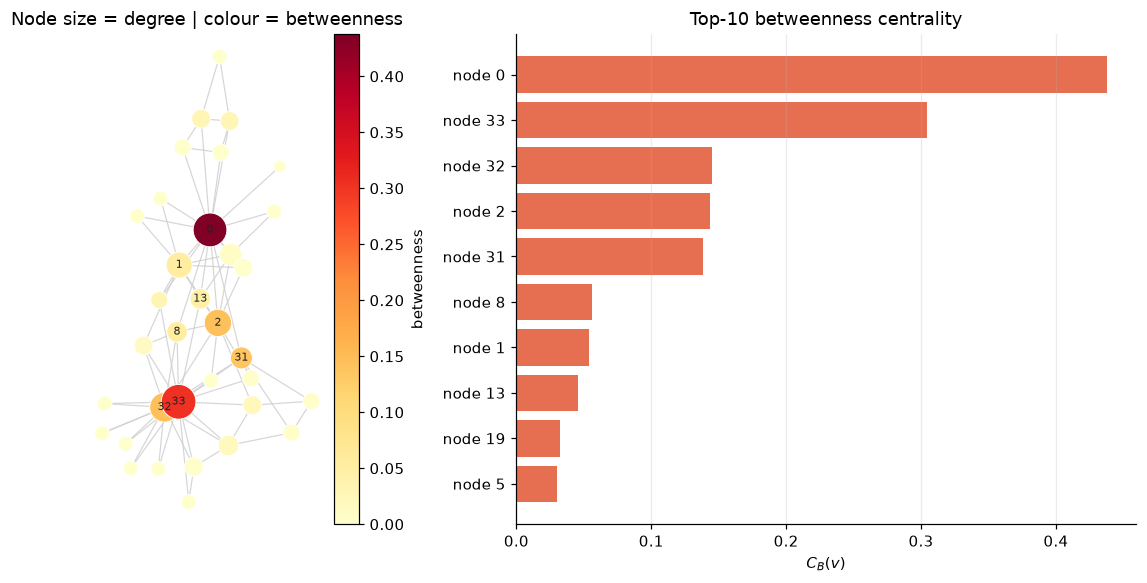

In [31]:
def fruchterman_reingold(g, iterations=400, seed=SEED):
    """Force-directed layout: repulsion ~ k^2/d, attraction ~ d^2/k."""
    rng = np.random.default_rng(seed)
    nodes = g.nodes()
    n = len(nodes)
    idx = {u: i for i, u in enumerate(nodes)}
    pos = rng.normal(0, 0.05, (n, 2)) + np.array(
        [[np.cos(2 * np.pi * i / n), np.sin(2 * np.pi * i / n)] for i in range(n)])
    k = np.sqrt(1.0 / n)          # ideal distance
    t = 0.15                      # initial temperature
    edges = [(idx[u], idx[v]) for u, v in g.edge_list()]

    for _ in range(iterations):
        delta = pos[:, None, :] - pos[None, :, :]
        dist = np.linalg.norm(delta, axis=2)
        np.fill_diagonal(dist, np.inf)
        disp = ((k ** 2 / dist ** 2)[:, :, None] * delta).sum(axis=1)
        for i, j in edges:
            d = pos[i] - pos[j]
            dn = np.linalg.norm(d) + 1e-12
            f = (dn ** 2 / k) * d / dn
            disp[i] -= f
            disp[j] += f
        length = np.linalg.norm(disp, axis=1, keepdims=True)
        length[length < 1e-12] = 1.0
        pos += disp / length * np.minimum(length, t)
        t *= 0.99
    pos -= pos.mean(axis=0)
    return pos / np.abs(pos).max()


def plot_graph(ax, g, pos, colors="tab:blue", sizes=60, cmap=None, vmin=None, vmax=None,
               edge_color="#cfcfcf", labels=None, label_size=7, edge_width=0.8):
    for u, v in g.edge_list():
        ax.plot([pos[u, 0], pos[v, 0]], [pos[u, 1], pos[v, 1]],
                color=edge_color, lw=edge_width, zorder=1, alpha=0.85)
    xy = np.array([pos[u] for u in g.nodes()])
    sc = ax.scatter(xy[:, 0], xy[:, 1], s=sizes, c=colors, cmap=cmap,
                    vmin=vmin, vmax=vmax, edgecolors="white", linewidths=0.6, zorder=2)
    if labels:
        for u in labels:
            ax.annotate(str(u), pos[u], fontsize=label_size, ha="center", va="center",
                        zorder=3, color="#222222")
    ax.set_aspect("equal")
    ax.axis("off")
    return sc


POS = fruchterman_reingold(G)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
top_labels = set(sorted(G.nodes(), key=btw.get, reverse=True)[:8])
sizes = 40 + 28 * np.array([G.degree(u) for u in G.nodes()])
sc = plot_graph(axes[0], G, POS, colors=[btw[u] for u in G.nodes()],
                sizes=sizes, cmap="YlOrRd", vmin=0, labels=top_labels)
axes[0].set_title("Node size = degree | colour = betweenness")
fig.colorbar(sc, ax=axes[0], fraction=0.04, pad=0.02, label="betweenness")

top = sorted(G.nodes(), key=btw.get, reverse=True)[:10]
axes[1].barh([f"node {u}" for u in top][::-1], [btw[u] for u in top][::-1], color="#e76f51")
axes[1].set_title("Top-10 betweenness centrality")
axes[1].set_xlabel("$C_B(v)$")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "02_centrality_network.png")
plt.show()

## 8. PageRank: importance by random walk

PageRank models a **random surfer**: with probability $\alpha$ (the damping factor, usually $0.85$)
they follow a random outgoing edge, otherwise they jump to a uniformly random node.

The stationary distribution of that Markov chain satisfies

$$PR(v) = \alpha \sum_{u \to v} \frac{PR(u)}{\deg(u)} + \frac{1-\alpha}{n}.$$

In matrix form, with $P = D^{-1}A$ the row-stochastic transition matrix,

$$\mathbf{pr} = \alpha P^{\top}\mathbf{pr} + \frac{1-\alpha}{n}\mathbf{1}.$$

We solve it by **power iteration** (the same idea as the original Google implementation): start from a
uniform vector and repeat until the L1 change is below $10^{-12}$. This costs
$O(k(V+E))$ for $k$ iterations — much cheaper than the $O(V^3)$ direct solve. As a check, the fixed
point is also solved exactly with `numpy.linalg.solve`.

In [32]:
def pagerank(g, alpha=0.85, tol=1e-12, max_iter=500):
    """Power iteration for pr = alpha * P^T pr + (1 - alpha)/n * 1."""
    nodes = g.nodes()
    n = len(nodes)
    idx = {u: i for i, u in enumerate(nodes)}
    A_ = g.adjacency_matrix(order=nodes)
    out_deg = A_.sum(axis=1)
    x = np.full(n, 1.0 / n)
    history = []
    for _ in range(max_iter):
        safe = np.where(out_deg > 0, out_deg, 1.0)
        contrib = A_.T @ (x / safe)
        dangling = x[out_deg == 0].sum()
        x_new = alpha * contrib + alpha * dangling / n + (1 - alpha) / n
        err = np.abs(x_new - x).sum()
        history.append(err)
        x = x_new
        if err < tol:
            break
    return {u: x[idx[u]] for u in nodes}, history


t0 = time.perf_counter()
pr, pr_hist = pagerank(G)
t_pr = time.perf_counter() - t0

print(f"PageRank converged in {len(pr_hist)} power iterations ({t_pr * 1000:.1f} ms)")
print(f"Final L1 residual: {pr_hist[-1]:.2e}")
print(f"Sum of scores    : {sum(pr.values()):.6f}")
print("Top-6:", [(u, round(pr[u], 4)) for u in sorted(pr, key=pr.get, reverse=True)[:6]])

# Independent check: solve the linear fixed point (I - alpha P^T) x = (1-alpha)/n 1
A_ = G.adjacency_matrix(order=G.nodes())
P = A_ / A_.sum(axis=1, keepdims=True)
x_exact = np.linalg.solve(np.eye(len(G)) - 0.85 * P.T, np.full(len(G), 0.15 / len(G)))
ours = np.array([pr[u] for u in G.nodes()])
print(f"Max |power iteration - linear solve| = {np.max(np.abs(ours - x_exact)):.2e}")

PageRank converged in 75 power iterations (3.2 ms)
Final L1 residual: 8.56e-13
Sum of scores    : 1.000000
Top-6: [(33, np.float64(0.1009)), (0, np.float64(0.097)), (32, np.float64(0.0717)), (2, np.float64(0.0571)), (1, np.float64(0.0529)), (31, np.float64(0.0372))]
Max |power iteration - linear solve| = 2.67e-13


saved -> figures\03_pagerank.png


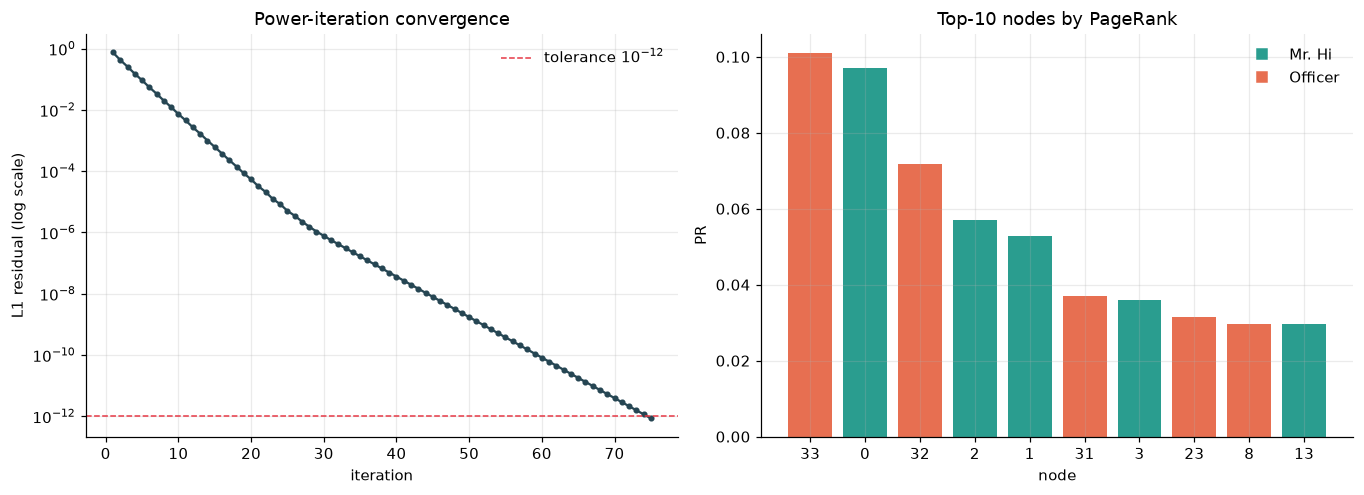

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].semilogy(range(1, len(pr_hist) + 1), pr_hist, "o-", ms=3, color="#264653")
axes[0].set_title("Power-iteration convergence")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("L1 residual (log scale)")
axes[0].axhline(1e-12, color="#e63946", ls="--", lw=1, label="tolerance $10^{-12}$")
axes[0].legend(frameon=False)

top = sorted(G.nodes(), key=pr.get, reverse=True)[:10]
colors = ["#2a9d8f" if FACTION[u] == 0 else "#e76f51" for u in top]
axes[1].bar(range(len(top)), [pr[u] for u in top], color=colors)
axes[1].set_xticks(range(len(top)))
axes[1].set_xticklabels([str(u) for u in top])
axes[1].set_title("Top-10 nodes by PageRank")
axes[1].set_xlabel("node")
axes[1].set_ylabel("PR")
handles = [Line2D([0], [0], marker="s", ls="", color=c, label=l)
           for c, l in [("#2a9d8f", "Mr. Hi"), ("#e76f51", "Officer")]]
axes[1].legend(handles=handles, frameon=False)

fig.tight_layout()
savefig(fig, "03_pagerank.png")
plt.show()

## 9. Community detection

A **community** is a set of nodes that is densely connected internally and sparsely connected to the
rest. The standard quality score is **Newman–Girvan modularity**:

$$Q = \frac{1}{2m}\sum_{i,j}\left[A_{ij} - \frac{k_i k_j}{2m}\right]\delta(c_i, c_j)$$

The term $k_i k_j / 2m$ is the number of edges we would *expect* between $i$ and $j$ if edges were
placed at random while keeping the degrees fixed. $Q$ is therefore "observed minus expected" inside
communities, and $Q \approx 0$ means no structure.

### Method 1 — Girvan–Newman (divisive, based on edge betweenness)

1. Compute the **betweenness of every edge** (how many shortest paths use it).
2. Remove the edge with the highest score — it is the most likely "bridge" between communities.
3. Recompute, and repeat.

This is the edge version of Brandes' algorithm, so one full sweep is $O(VE)$; removing up to $m$ edges
gives $O(m^2V)$ overall. We record $Q$ after every cut and keep the partition with the best score.

### Method 2 — Spectral clustering + k-means (the AI/ML part)

Build the **normalised Laplacian** $L_{sym} = I - D^{-1/2}AD^{-1/2}$ and take its eigenvectors. The
second-smallest eigenvalue $\lambda_2$ (**algebraic connectivity**, or Fiedler value) measures how
close the graph is to splitting; its eigenvector already separates the two groups. We embed every node
in the space of the bottom eigenvectors and run **k-means++** on those coordinates.

This is exactly the "clustering algorithm to identify communities with similar connection patterns"
that the project brief asks for: the graph is converted into a geometric point cloud, then clustered.

Two implementations are compared below, because the literature uses both conventions:

* **Fiedler variant (used as the main method).** Take eigenvectors $2,\ldots,k+1$ of $L_{sym}$ and
  skip the trivial eigenvector $\mathbf{1}$ (eigenvalue $0$). For $k=2$ this is the classical Fiedler
  vector; for $k>2$ it is the natural extension used in most spectral-clustering tutorials.
* **Literal Ng–Jordan–Weiss (NJW).** Take the $k$ *smallest* eigenvectors, $1,\ldots,k$, i.e. include
  the constant eigenvector as well, then row-normalise. This is the literal algorithm of Ng, Jordan &
  Weiss (2001).

The only difference is whether the constant vector is included. Including it adds a coordinate that is
identical for every node, so it carries **no cluster information**; after row normalisation, however,
it changes the geometry of the point cloud and therefore which local optimum k-means reaches. The
experiment below measures that effect instead of assuming it away.

In [34]:
def modularity(g, communities):
    """Newman-Girvan modularity of a partition."""
    m = g.number_of_edges()
    if m == 0:
        return 0.0
    A_ = g.adjacency_matrix()
    k = A_.sum(axis=1)
    nodes = g.nodes()
    idx = {u: i for i, u in enumerate(nodes)}
    Q = 0.0
    for comm in communities:
        ii = np.array([idx[u] for u in comm], dtype=int)
        internal = A_[np.ix_(ii, ii)].sum()      # counts each internal edge twice
        Q += internal - k[ii].sum() ** 2 / (2 * m)
    return Q / (2 * m)


def edge_betweenness(g):
    """Brandes accumulation of shortest-path counts onto edges."""
    nodes = g.nodes()
    eb = {(u, v): 0.0 for u, v in g.edge_list()}
    for s in nodes:
        S, P = [], {w: [] for w in nodes}
        sigma = dict.fromkeys(nodes, 0)
        sigma[s] = 1
        dist = dict.fromkeys(nodes, -1)
        dist[s] = 0
        q = deque([s])
        while q:
            v = q.popleft()
            S.append(v)
            for w in g.neighbors(v):
                if dist[w] < 0:
                    dist[w] = dist[v] + 1
                    q.append(w)
                if dist[w] == dist[v] + 1:
                    sigma[w] += sigma[v]
                    P[w].append(v)
        delta = dict.fromkeys(nodes, 0.0)
        while S:
            w = S.pop()
            for v in P[w]:
                c = sigma[v] / sigma[w] * (1 + delta[w])
                delta[v] += c
                key = (v, w) if v < w else (w, v)
                eb[key] += c
    return {e: val / 2 for e, val in eb.items()}   # every pair is seen from both ends


def girvan_newman(g):
    """Cut the strongest edge repeatedly; track the first 2-way split and the best-Q partition."""
    work = g.copy()
    best_q, best_comms, q_curve = -np.inf, None, []
    two_way, two_way_q = None, None
    while work.number_of_edges() > 0:
        eb = edge_betweenness(work)
        u, v = max(sorted(eb), key=eb.get)
        work.remove_edge(u, v)
        comps = connected_components(work)
        q = modularity(g, comps)
        q_curve.append(q)
        if two_way is None and len(comps) == 2:
            two_way, two_way_q = comps, q
        if q > best_q:
            best_q, best_comms = q, comps
        if len(comps) == len(g):
            break
    return best_comms, best_q, q_curve, two_way, two_way_q


def adjusted_rand_index(a, b):
    """ARI: 1 = identical partitions, 0 = chance level. Permutation invariant."""
    a, b = np.asarray(a), np.asarray(b)
    _, ia = np.unique(a, return_inverse=True)
    _, ib = np.unique(b, return_inverse=True)
    M = np.zeros((ia.max() + 1, ib.max() + 1))
    np.add.at(M, (ia, ib), 1)
    comb = lambda x: x * (x - 1) / 2
    n = len(a)
    index = comb(M).sum()
    expected = comb(M.sum(1)).sum() * comb(M.sum(0)).sum() / comb(n)
    maximum = (comb(M.sum(1)).sum() + comb(M.sum(0)).sum()) / 2
    return (index - expected) / (maximum - expected) if maximum != expected else 1.0


t0 = time.perf_counter()
gn_comms, gn_q, q_curve, gn2_comms, gn2_q = girvan_newman(G)
t_gn = time.perf_counter() - t0

def labels_of(comms, n=None):
    if n is None:
        n = max(max(c) for c in comms if c) + 1 if any(comms) else 0
    labels = np.zeros(n, dtype=int)
    for cid, comm in enumerate(sorted(comms, key=min)):
        for u in comm:
            labels[u] = cid
    return labels


gn_labels = labels_of(gn_comms)
gn2_labels = labels_of(gn2_comms)

print(f"Girvan-Newman: {len(gn_comms)} communities at maximum Q = {gn_q:.4f} "
      f"({t_gn * 1000:.0f} ms)")
print("Community sizes at max Q:", sorted([len(c) for c in gn_comms], reverse=True))
print(f"  ARI vs historical factions: {adjusted_rand_index(gn_labels, FACTION):.3f}")
print(f"First 2-way split: Q = {gn2_q:.4f}, "
      f"ARI = {adjusted_rand_index(gn2_labels, FACTION):.3f}")

Girvan-Newman: 5 communities at maximum Q = 0.4013 (70 ms)
Community sizes at max Q: [12, 10, 6, 5, 1]
  ARI vs historical factions: 0.469
First 2-way split: Q = 0.3600, ARI = 0.882


In [35]:
def spectral_embedding(g, k=2, include_trivial=False):
    """Bottom eigenvectors of L_sym = I - D^-1/2 A D^-1/2, rows normalised.

    include_trivial=False -> eigenvectors 2..k+1  (Fiedler vector + extension)
    include_trivial=True  -> eigenvectors 1..k    (literal Ng-Jordan-Weiss)
    """
    A_ = g.adjacency_matrix()
    d = A_.sum(axis=1)
    inv = np.divide(1.0, np.sqrt(d), out=np.zeros_like(d), where=d > 0)
    L = np.eye(len(d)) - inv[:, None] * A_ * inv[None, :]
    eigvals, eigvecs = np.linalg.eigh(L)
    start = 0 if include_trivial else 1
    X = eigvecs[:, start:start + k]
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    return eigvals, X / np.where(norms > 0, norms, 1.0)


def kmeans(X, k, n_init=25, max_iter=200, seed=SEED):
    """k-means++ initialisation + Lloyd iterations, from scratch."""
    rng = np.random.default_rng(seed)
    best_inertia, best_labels = np.inf, None
    for _ in range(n_init):
        centers = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = ((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(-1).min(1)
            probs = d2 / d2.sum() if d2.sum() > 0 else np.full(len(X), 1 / len(X))
            centers.append(X[rng.choice(len(X), p=probs)])
        C = np.array(centers)
        for _ in range(max_iter):
            labels = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[labels == j].mean(0) if np.any(labels == j) else C[j]
                             for j in range(k)])
            if np.allclose(newC, C):
                C = newC
                break
            C = newC
        inertia = ((X - C[labels]) ** 2).sum()
        if inertia < best_inertia:
            best_inertia, best_labels = inertia, labels
    return best_labels


def spectral_partition(g, k, include_trivial=False, seed=SEED):
    """Embed, cluster, and return (labels, communities, eigenvalues)."""
    vals, emb = spectral_embedding(g, k=k, include_trivial=include_trivial)
    labels = kmeans(emb, k, seed=seed)
    comms = [list(np.where(labels == c)[0]) for c in range(k)]
    return labels, comms, vals


t0 = time.perf_counter()
spec_labels, spec_comms, eigvals = spectral_partition(G, 2)
t_spec = time.perf_counter() - t0
spec_q = modularity(G, spec_comms)

t0 = time.perf_counter()
spec4_labels, spec4_comms, _ = spectral_partition(G, 4)
spec4_q = modularity(G, spec4_comms)
t_spec4 = time.perf_counter() - t0

t0 = time.perf_counter()
njw2_labels, njw2_comms, _ = spectral_partition(G, 2, include_trivial=True)
njw2_q = modularity(G, njw2_comms)
t_njw2 = time.perf_counter() - t0

t0 = time.perf_counter()
njw4_labels, njw4_comms, _ = spectral_partition(G, 4, include_trivial=True)
njw4_q = modularity(G, njw4_comms)
t_njw4 = time.perf_counter() - t0

print("Smallest Laplacian eigenvalues:", np.round(eigvals[:5], 4))
print(f"Fiedler value (algebraic connectivity) = {eigvals[1]:.4f}")
print(f"Fiedler  k=2: Q = {spec_q:.4f}, ARI = {adjusted_rand_index(spec_labels, FACTION):.4f}")
print(f"Literal NJW k=2: Q = {njw2_q:.4f}, ARI = {adjusted_rand_index(njw2_labels, FACTION):.4f}")
print(f"Fiedler  k=4: Q = {spec4_q:.4f}, ARI = {adjusted_rand_index(spec4_labels, FACTION):.4f}")
print(f"Literal NJW k=4: Q = {njw4_q:.4f}, ARI = {adjusted_rand_index(njw4_labels, FACTION):.4f}")

results = pd.DataFrame([
    {"method": "Girvan-Newman (first split)", "eigenvectors": "-", "communities": 2,
     "modularity Q": gn2_q, "ARI vs truth": adjusted_rand_index(gn2_labels, FACTION),
     "time (ms)": t_gn * 1000},
    {"method": "Girvan-Newman (max Q)", "eigenvectors": "-", "communities": len(gn_comms),
     "modularity Q": gn_q, "ARI vs truth": adjusted_rand_index(gn_labels, FACTION),
     "time (ms)": np.nan},
    {"method": "Spectral, Fiedler variant", "eigenvectors": "2..k+1", "communities": 2,
     "modularity Q": spec_q, "ARI vs truth": adjusted_rand_index(spec_labels, FACTION),
     "time (ms)": t_spec * 1000},
    {"method": "Spectral, literal NJW", "eigenvectors": "1..k", "communities": 2,
     "modularity Q": njw2_q, "ARI vs truth": adjusted_rand_index(njw2_labels, FACTION),
     "time (ms)": t_njw2 * 1000},
    {"method": "Spectral, Fiedler variant", "eigenvectors": "2..k+1", "communities": 4,
     "modularity Q": spec4_q, "ARI vs truth": adjusted_rand_index(spec4_labels, FACTION),
     "time (ms)": t_spec4 * 1000},
    {"method": "Spectral, literal NJW", "eigenvectors": "1..k", "communities": 4,
     "modularity Q": njw4_q, "ARI vs truth": adjusted_rand_index(njw4_labels, FACTION),
     "time (ms)": t_njw4 * 1000},
])
results.round(4)

Smallest Laplacian eigenvalues: [-0.      0.1323  0.287   0.3873  0.6122]
Fiedler value (algebraic connectivity) = 0.1323
Fiedler  k=2: Q = 0.3715, ARI = 1.0000
Literal NJW k=2: Q = 0.3600, ARI = 0.8823
Fiedler  k=4: Q = 0.4013, ARI = 0.5231
Literal NJW k=4: Q = 0.4198, ARI = 0.5414


,method,eigenvectors,communities,modularity Q,ARI vs truth,time (ms)
0,Girvan-Newman (first split),-,2,0.3600,0.8823,70.2267
1,Girvan-Newman (max Q),-,5,0.4013,0.4686,NaN
2,"Spectral, Fiedler variant",2..k+1,2,0.3715,1.0000,4.8411
3,"Spectral, literal NJW",1..k,2,0.3600,0.8823,3.9084
4,"Spectral, Fiedler variant",2..k+1,4,0.4013,0.5231,9.8001
5,"Spectral, literal NJW",1..k,4,0.4198,0.5414,7.0669


saved -> figures\04_communities.png


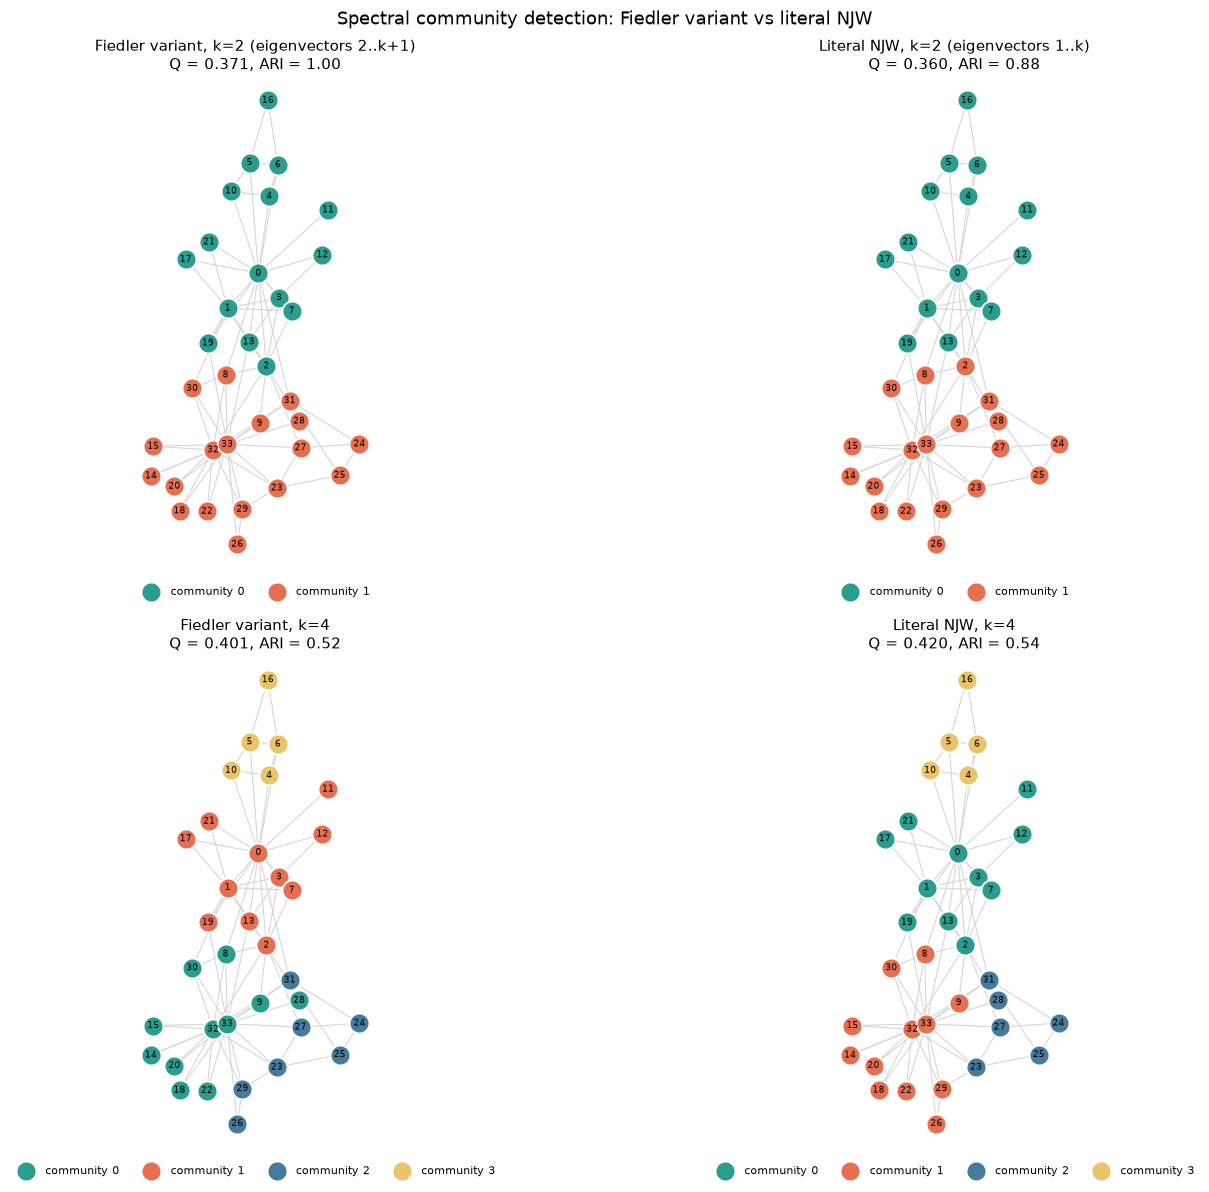

Girvan-Newman first split vs the real factions
  community 0: 15 nodes | Mr. Hi 15 / Officer  0
  community 1: 19 nodes | Mr. Hi  1 / Officer 18

Spectral Fiedler k=2 vs the real factions
  community 0: 16 nodes | Mr. Hi 16 / Officer  0
  community 1: 18 nodes | Mr. Hi  0 / Officer 18

Spectral literal NJW k=2 vs the real factions
  community 0: 15 nodes | Mr. Hi 15 / Officer  0
  community 1: 19 nodes | Mr. Hi  1 / Officer 18


In [36]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
palette = ["#2a9d8f", "#e76f51", "#457b9d", "#e9c46a", "#9b5de5", "#f4a261"]
panels = [
    (axes[0, 0], spec_labels, "Fiedler variant, k=2 (eigenvectors 2..k+1)", spec_q),
    (axes[0, 1], njw2_labels, "Literal NJW, k=2 (eigenvectors 1..k)", njw2_q),
    (axes[1, 0], spec4_labels, "Fiedler variant, k=4", spec4_q),
    (axes[1, 1], njw4_labels, "Literal NJW, k=4", njw4_q),
]

for ax, (labels, title, q) in zip([p[0] for p in panels],
                                  [(p[1], p[2], p[3]) for p in panels]):
    for u, v in G.edge_list():
        ax.plot([POS[u, 0], POS[v, 0]], [POS[u, 1], POS[v, 1]],
                color="#d5d5d5", lw=0.7, zorder=1)
    for c in sorted(set(labels)):
        members = [u for u in G.nodes() if labels[u] == c]
        ax.scatter(POS[members, 0], POS[members, 1], s=170, color=palette[c],
                   edgecolors="white", linewidths=1.2, label=f"community {c}", zorder=3)
    for u in G.nodes():
        ax.annotate(str(u), POS[u], fontsize=6.2, ha="center", va="center", zorder=4)
    ar = adjusted_rand_index(labels, FACTION)
    ax.set_title(f"{title}\nQ = {q:.3f}, ARI = {ar:.2f}", fontsize=10)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.02),
              ncol=min(len(set(labels)), 4), fontsize=7)

fig.suptitle("Spectral community detection: Fiedler variant vs literal NJW")
fig.tight_layout()
savefig(fig, "04_communities.png")
plt.show()


def faction_breakdown(labels, name):
    print(f"{name} vs the real factions")
    for c in sorted(set(labels)):
        members = [u for u in G.nodes() if labels[u] == c]
        hi = sum(FACTION[u] == 0 for u in members)
        print(f"  community {c}: {len(members):2d} nodes | Mr. Hi {hi:2d} / Officer {len(members) - hi:2d}")


faction_breakdown(gn2_labels, "Girvan-Newman first split")
print()
faction_breakdown(spec_labels, "Spectral Fiedler k=2")
print()
faction_breakdown(njw2_labels, "Spectral literal NJW k=2")

## 10. Application: how fragile is the network?

Centrality is not just a ranking exercise. If the high-betweenness nodes really are **bridges**, then
removing them should break the network into disconnected pieces, while removing random members should
barely matter. This is the mathematical basis of:

* **targeted immunisation** — vaccinate the hubs to stop an epidemic;
* **network resilience** — find single points of failure in a communication system;
* **fraud / botnet detection** — the brokers are the accounts that link otherwise separate groups.

We simulate the removal of $k = 0 \ldots 12$ nodes chosen by (i) betweenness, (ii) degree,
(iii) PageRank, and (iv) at random (average of 30 runs), and measure the **largest connected
component** after each step, using the BFS component routine from Section 6.

**Two denominators matter, and they answer different questions.**

* **Fraction of remaining nodes** $= |C_{\max}| \,/\, (n-k)$ asks: *after the attack, is what is left
  still one piece?* This is the standard percolation-style measure and is comparable across networks
  of different sizes.
* **Fraction of the original network** $= |C_{\max}| \,/\, n$ asks: *how much of the original network is
  still connected?* It also counts the nodes that were deleted, so it always falls even when the
  remaining graph stays connected.

Reporting only the first number can make an attack look harmless ("90% of what remains is connected")
when a large part of the original network has actually been removed. Both are reported below.

saved -> figures\05_robustness.png


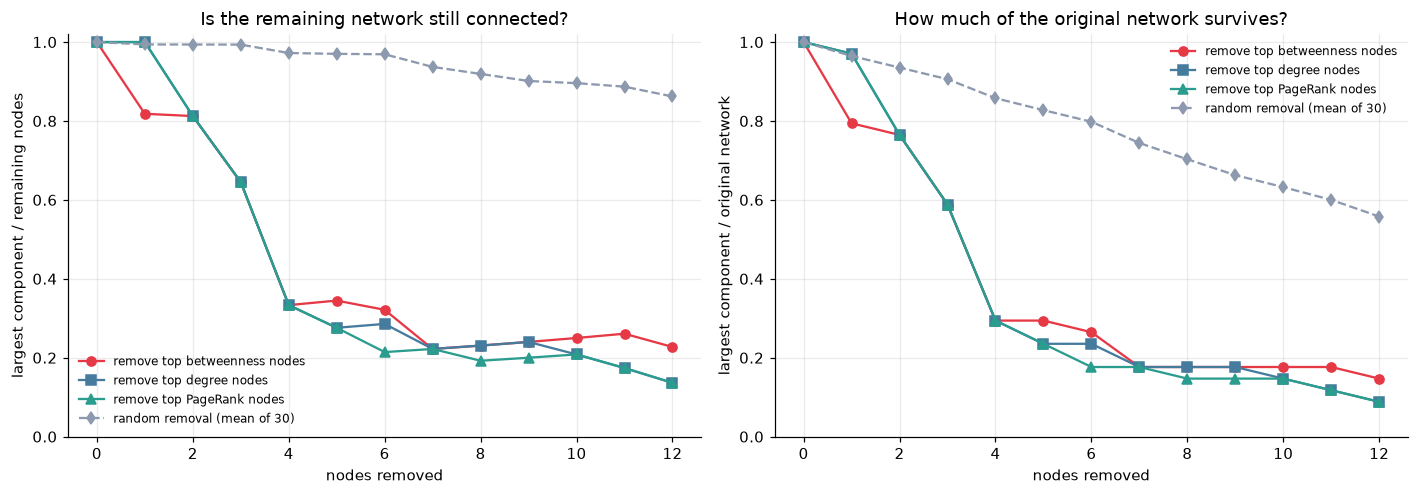

After removing 5 highest-betweenness nodes (29 remain): 34.5% of remaining, 29.4% of original
After removing 5 highest-degree nodes     (29 remain): 27.6% of remaining, 23.5% of original
After removing 5 highest-PageRank nodes   (29 remain): 27.6% of remaining, 23.5% of original
After removing 5 random nodes             (29 remain): 97.0% of remaining, 82.7% of original


In [37]:
def attack(g, ranking, steps):
    """Remove the top-k nodes; return (giant/remaining, giant/original) for every k."""
    n0 = len(g)
    order = sorted(ranking, key=ranking.get, reverse=True)
    out = []
    for k in steps:
        h = g.copy()
        for u in order[:k]:
            h.remove_node(u)
        comps_h = connected_components(h)
        giant = len(comps_h[0]) if comps_h else 0
        out.append((giant / len(h) if len(h) else 0.0, giant / n0))
    return out


steps = list(range(0, 13))
attack_btw = attack(G, btw, steps)
attack_degree = attack(G, deg, steps)
attack_pr = attack(G, pr, steps)

rng = np.random.default_rng(SEED)
random_runs = []
for _ in range(30):
    perm = {u: rng.random() for u in G.nodes()}
    random_runs.append(attack(G, perm, steps))
random_curve = np.mean(random_runs, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, idx, ylabel in [
    (axes[0], 0, "largest component / remaining nodes"),
    (axes[1], 1, "largest component / original network"),
]:
    ax.plot(steps, [x[idx] for x in attack_btw], "o-", color="#e63946",
            label="remove top betweenness nodes")
    ax.plot(steps, [x[idx] for x in attack_degree], "s-", color="#457b9d",
            label="remove top degree nodes")
    ax.plot(steps, [x[idx] for x in attack_pr], "^-", color="#2a9d8f",
            label="remove top PageRank nodes")
    ax.plot(steps, random_curve[:, idx], "d--", color="#8d99ae",
            label="random removal (mean of 30)")
    ax.set_xlabel("nodes removed")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_title("Is the remaining network still connected?")
axes[1].set_title("How much of the original network survives?")
fig.tight_layout()
savefig(fig, "05_robustness.png")
plt.show()

print(f"After removing 5 highest-betweenness nodes ({len(G) - 5} remain): "
      f"{attack_btw[5][0]:.1%} of remaining, {attack_btw[5][1]:.1%} of original")
print(f"After removing 5 highest-degree nodes     ({len(G) - 5} remain): "
      f"{attack_degree[5][0]:.1%} of remaining, {attack_degree[5][1]:.1%} of original")
print(f"After removing 5 highest-PageRank nodes   ({len(G) - 5} remain): "
      f"{attack_pr[5][0]:.1%} of remaining, {attack_pr[5][1]:.1%} of original")
print(f"After removing 5 random nodes             ({len(G) - 5} remain): "
      f"{random_curve[5, 0]:.1%} of remaining, {random_curve[5, 1]:.1%} of original")

## 11. Verification against NetworkX

To prove the implementations are correct (and not just plausible-looking), every score is compared
with NetworkX on the same edge list. Differences should be at the level of floating-point noise
($\sim 10^{-15}$).

In [38]:
try:
    import networkx as nx

    H = nx.Graph()
    H.add_nodes_from(range(len(G)))
    H.add_edges_from(G.edge_list())

    checks = [
        ("degree centrality",
         max(abs(deg[u] - nx.degree_centrality(H)[u]) for u in G.nodes())),
        ("closeness centrality",
         max(abs(clo[u] - nx.closeness_centrality(H)[u]) for u in G.nodes())),
        ("betweenness centrality",
         max(abs(btw[u] - nx.betweenness_centrality(H, normalized=True)[u]) for u in G.nodes())),
        ("PageRank",
         max(abs(pr[u] - nx.pagerank(H, alpha=0.85, tol=1e-12)[u]) for u in G.nodes())),
        ("modularity (our partition)",
         abs(gn_q - nx.community.modularity(H, gn_comms))),
        ("number of components",
         abs(len(comps) - nx.number_connected_components(H))),
    ]
    verification = pd.DataFrame(checks, columns=["quantity", "max |ours - NetworkX|"])
    verification["max |ours - NetworkX|"] = verification["max |ours - NetworkX|"].map(
        lambda x: f"{x:.2e}")
    display(verification)
except ImportError:
    print("NetworkX is not installed - skipping the independent cross-check.")
    print("(Colab ships with it, so the check runs there by default.)")

,quantity,max |ours - NetworkX|
0,degree centrality,0.00e+00
1,closeness centrality,0.00e+00
2,betweenness centrality,5.20e-18
3,PageRank,1.00e-11
4,modularity (our partition),5.55e-17
5,number of components,0.00e+00


### 12. Do the centrality metrics agree? Pearson and Spearman

If all centrality measures produced the same ranking they would be redundant. Two different questions
are asked of the same data:

* **Pearson correlation** measures the strength of a **linear** relationship between the raw scores.
  It is sensitive to the heavy right tail of centrality distributions: one hub with a very large score
  can dominate the coefficient.
* **Spearman rank correlation** replaces every score by its rank and then computes Pearson on the
  ranks. It measures **monotone** agreement and therefore answers the practical question — do the two
  metrics order the nodes the same way? — without assuming linearity or well-behaved tails.

A third, more decision-oriented measure is the **top-10 overlap**: of the ten highest-ranked nodes by
metric A, how many also appear in the top ten by metric B? Executives and analysts rarely care about
the bottom of the ranking, so this captures whether the metrics would lead to the same shortlist.

All six pairs are reported for the karate club. The same analysis is repeated on the football network
in Section 13, so the values can be compared across datasets.

,pair,Pearson r,Spearman rho,top-10 overlap
0,degree / closeness,0.772,0.895,0.9
1,degree / betweenness,0.915,0.905,0.8
2,degree / pagerank,0.998,0.979,1.0
3,closeness / betweenness,0.718,0.898,0.9
4,closeness / pagerank,0.742,0.825,0.9
5,betweenness / pagerank,0.923,0.879,0.8


saved -> figures\06_centrality_correlation.png


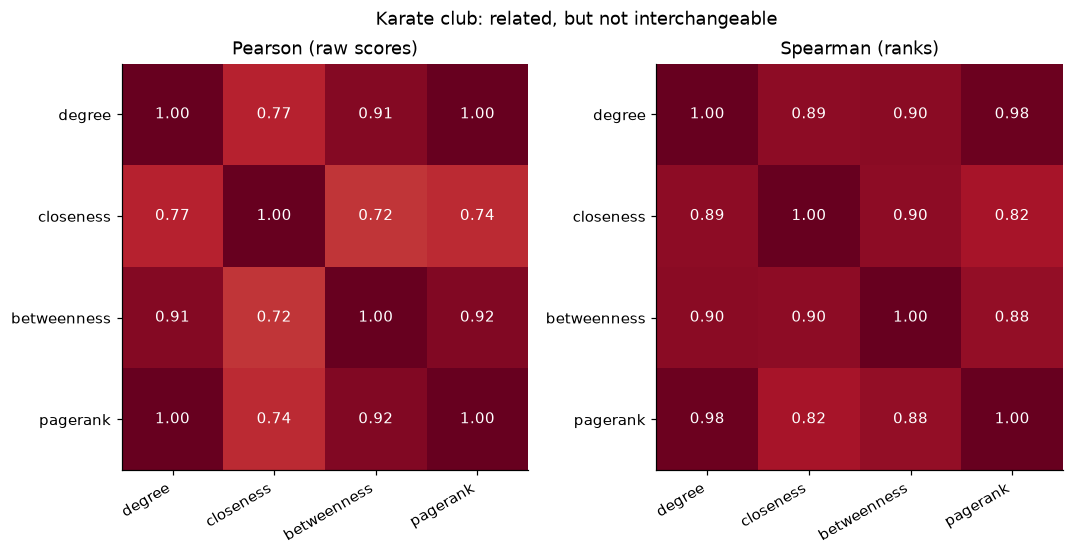

In [39]:
def rankdata(x):
    """Average ranks, ties handled (equivalent to scipy.stats.rankdata)."""
    x = np.asarray(x, dtype=float)
    sorter = np.argsort(x, kind="mergesort")
    ranks = np.empty(len(x), dtype=float)
    ranks[sorter] = np.arange(1, len(x) + 1, dtype=float)
    sorted_x = x[sorter]
    i = 0
    while i < len(x):
        j = i
        while j + 1 < len(x) and sorted_x[j + 1] == sorted_x[i]:
            j += 1
        if j > i:
            ranks[sorter[i:j + 1]] = (i + j + 2) / 2.0
        i = j + 1
    return ranks


def pearson(x, y):
    x = np.asarray(x, dtype=float) - np.mean(x)
    y = np.asarray(y, dtype=float) - np.mean(y)
    denom = np.sqrt((x @ x) * (y @ y))
    return float(x @ y / denom) if denom else 0.0


def spearman(x, y):
    return pearson(rankdata(x), rankdata(y))


def corr_frame(df, method="pearson"):
    cols = list(df.columns)
    f = pearson if method == "pearson" else spearman
    M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            r = f(df[a].values, df[b].values)
            M.loc[a, b] = M.loc[b, a] = r
    return M


def top_overlap(a, b, k=10):
    ta = set(pd.Series(np.asarray(a)).nlargest(k).index)
    tb = set(pd.Series(np.asarray(b)).nlargest(k).index)
    return len(ta & tb) / k


metrics = pd.DataFrame({
    "degree": [deg[u] for u in G.nodes()],
    "closeness": [clo[u] for u in G.nodes()],
    "betweenness": [btw[u] for u in G.nodes()],
    "pagerank": [pr[u] for u in G.nodes()],
})
pear = corr_frame(metrics, "pearson")
spear = corr_frame(metrics, "spearman")

PAIRS = [("degree", "closeness"), ("degree", "betweenness"), ("degree", "pagerank"),
         ("closeness", "betweenness"), ("closeness", "pagerank"), ("betweenness", "pagerank")]
pair_table = pd.DataFrame([
    {"pair": f"{a} / {b}",
     "Pearson r": pear.loc[a, b],
     "Spearman rho": spear.loc[a, b],
     "top-10 overlap": top_overlap(metrics[a], metrics[b])}
    for a, b in PAIRS
])
display(pair_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, M, title in [(axes[0], pear, "Pearson (raw scores)"),
                     (axes[1], spear, "Spearman (ranks)")]:
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(M)))
    ax.set_xticklabels(M.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(M)))
    ax.set_yticklabels(M.columns)
    for i in range(len(M)):
        for j in range(len(M)):
            ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(M.iloc[i, j]) > 0.6 else "#222222")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Karate club: related, but not interchangeable")
savefig(fig, "06_centrality_correlation.png")
plt.show()

## 13. A second, larger network: American college football

A single case study cannot tell us whether a result is a property of networks or a property of 34
karate players. The whole pipeline is therefore repeated on the **American college football network**:
115 teams, 613 games from the 2000 season, and 12 conferences. The ground truth is conference
membership, which again is used only for evaluation.

The football network is much larger ($3.4\times$ the nodes, $7.9\times$ the edges) but **sparser**
(density 0.0935 vs 0.139 for karate) and has a smaller diameter (4 vs 5). It is therefore a genuine
out-of-sample test of the algorithms, not a scaled copy of the same graph. Three questions are asked:

1. **Centrality** — are the same nodes important under degree, closeness, betweenness and PageRank, and
   do the rankings agree as strongly as they did on the karate club?
2. **Communities** — does spectral clustering recover the 12 conferences, and how does modularity
   behave as $k$ varies?
3. **Robustness** — is a larger, denser network harder to fragment than the karate club?

All four centralities on 115 nodes and 613 edges: 0.10 s
Components     : 1 (sizes [115])
Diameter       : 4
Average path   : 2.508
Density        : 0.0935
Average degree : 10.66
Conferences    : 12, sizes [13, 12, 12, 11, 10, 10, 10, 9, 8, 8, 7, 5]
saved -> figures\07_football_structure.png


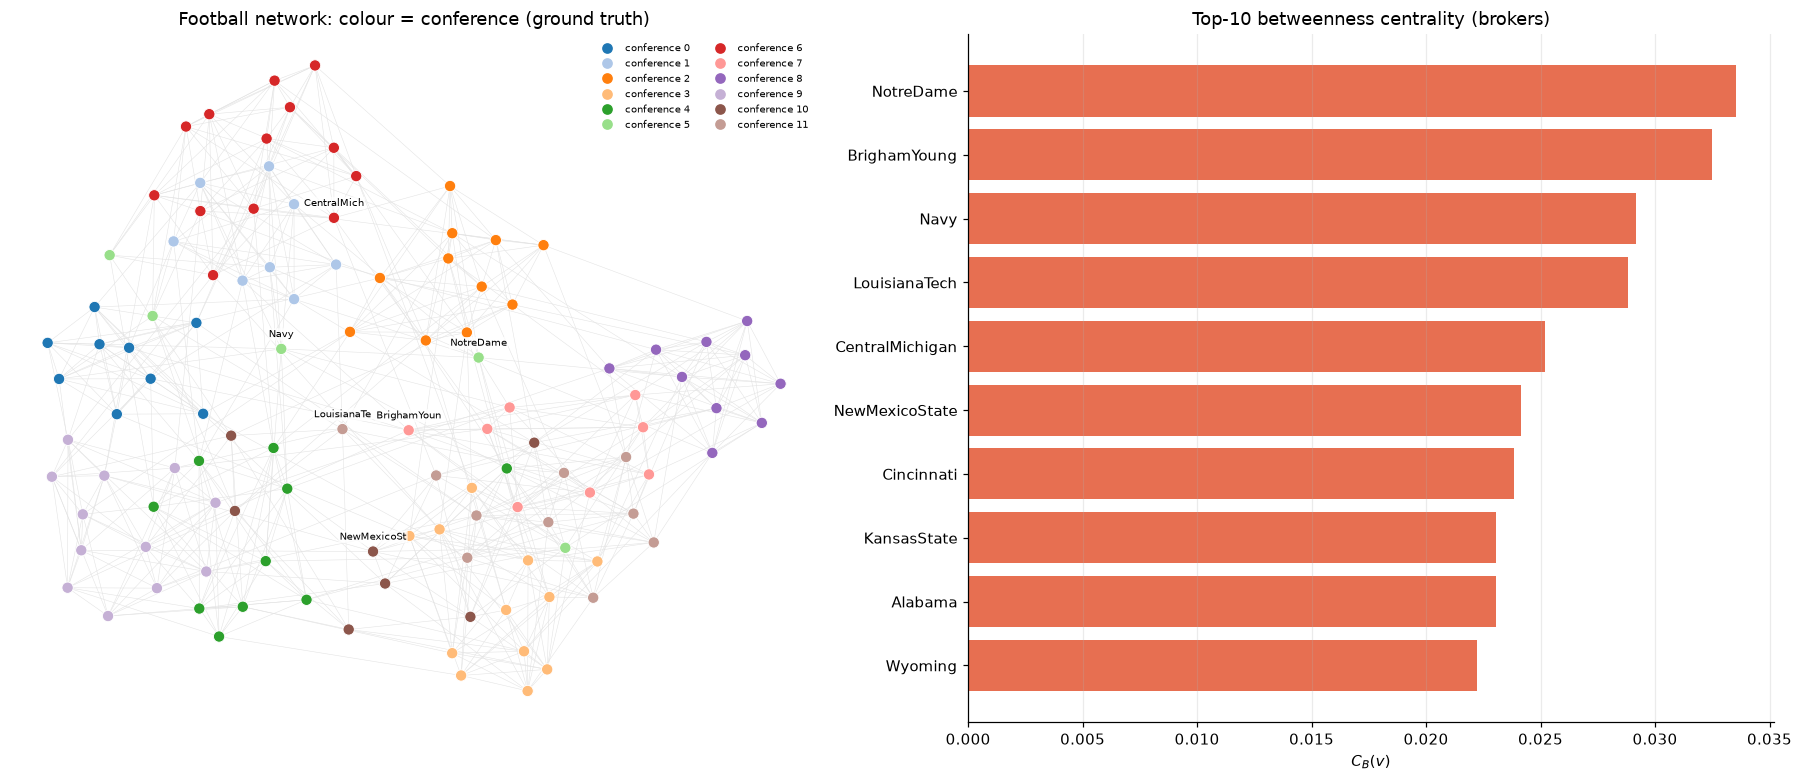

In [40]:
t0 = time.perf_counter()
fb_deg = degree_centrality(FB)
fb_clo = closeness_centrality(FB)
fb_btw = betweenness_centrality(FB)
fb_pr, fb_hist = pagerank(FB)
t_fb = time.perf_counter() - t0

fb_comps = connected_components(FB)
fb_dists = [bfs(FB, u)[1] for u in FB.nodes()]
fb_diam = max(max(d.values()) for d in fb_dists)
fb_avg_path = np.mean([d for dist in fb_dists for d in dist.values() if d > 0])

print(f"All four centralities on {len(FB)} nodes and {FB.number_of_edges()} edges: "
      f"{t_fb:.2f} s")
print(f"Components     : {len(fb_comps)} (sizes {[len(c) for c in fb_comps]})")
print(f"Diameter       : {fb_diam}")
print(f"Average path   : {fb_avg_path:.3f}")
print(f"Density        : {FB.density():.4f}")
print(f"Average degree : {2 * FB.number_of_edges() / len(FB):.2f}")
print(f"Conferences    : {len(set(FOOTBALL_CONF))}, sizes "
      f"{sorted([FOOTBALL_CONF.count(c) for c in range(12)], reverse=True)}")

POS_FB = fruchterman_reingold(FB, iterations=500, seed=SEED)
conf_colors = plt.get_cmap("tab20")(np.linspace(0, 1, 20))[:12]

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2))
for u, v in FB.edge_list():
    axes[0].plot([POS_FB[u, 0], POS_FB[v, 0]], [POS_FB[u, 1], POS_FB[v, 1]],
                 color="#e3e3e3", lw=0.35, zorder=1)
axes[0].scatter(POS_FB[:, 0], POS_FB[:, 1],
                c=[conf_colors[c] for c in FOOTBALL_CONF],
                s=55, edgecolors="white", linewidths=0.6, zorder=2)
for u in sorted(FB.nodes(), key=fb_btw.get, reverse=True)[:6]:
    axes[0].annotate(FB.meta[u]["name"][:11], (POS_FB[u, 0], POS_FB[u, 1] + 0.025),
                     fontsize=6.5, ha="center", va="bottom", zorder=5,
                     bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))
handles = [Line2D([0], [0], marker="o", ls="", color=conf_colors[c],
                  label=f"conference {c}") for c in range(12)]
axes[0].legend(handles=handles, frameon=False, fontsize=6.5, ncol=2, loc="upper right")
axes[0].set_title("Football network: colour = conference (ground truth)")
axes[0].axis("off")

fb_top_btw = sorted(FB.nodes(), key=fb_btw.get, reverse=True)[:10]
axes[1].barh([FB.meta[u]["name"] for u in fb_top_btw][::-1],
             [fb_btw[u] for u in fb_top_btw][::-1], color="#e76f51")
axes[1].set_title("Top-10 betweenness centrality (brokers)")
axes[1].set_xlabel("$C_B(v)$")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "07_football_structure.png")
plt.show()

### 13.1 Centrality rankings on the football network

The same four metrics are computed from scratch. The table lists the ten biggest brokers, and the
correlation analysis is repeated so that the karate and football results can be read side by side.

In [41]:
fb_metrics = pd.DataFrame({
    "degree": [fb_deg[u] for u in FB.nodes()],
    "closeness": [fb_clo[u] for u in FB.nodes()],
    "betweenness": [fb_btw[u] for u in FB.nodes()],
    "pagerank": [fb_pr[u] for u in FB.nodes()],
})
fb_pear = corr_frame(fb_metrics, "pearson")
fb_spear = corr_frame(fb_metrics, "spearman")

fb_rank_table = pd.DataFrame([
    {"rank": i + 1, "team": FB.meta[u]["name"], "conference": FB.meta[u]["conference"],
     "degree": fb_deg[u], "closeness": fb_clo[u],
     "betweenness": fb_btw[u], "pagerank": fb_pr[u]}
    for i, u in enumerate(fb_top_btw)
])
display(fb_rank_table.round(4))

fb_top_deg = sorted(FB.nodes(), key=fb_deg.get, reverse=True)[:10]
print("Top-10 by degree     :", [FB.meta[u]["name"] for u in fb_top_deg])
print("Top-10 by betweenness:", [FB.meta[u]["name"] for u in fb_top_btw])
print(f"Overlap of the two top-10 lists: {top_overlap(fb_metrics['degree'], fb_metrics['betweenness']):.0%}")

cross = pd.DataFrame([
    {"pair": f"{a} / {b}",
     "Karate Pearson": pear.loc[a, b],
     "Karate Spearman": spear.loc[a, b],
     "Karate top-10": top_overlap(metrics[a], metrics[b]),
     "Football Pearson": fb_pear.loc[a, b],
     "Football Spearman": fb_spear.loc[a, b],
     "Football top-10": top_overlap(fb_metrics[a], fb_metrics[b])}
    for a, b in PAIRS
])
display(cross.round(3))

,rank,team,conference,degree,closeness,betweenness,pagerank
0,1,NotreDame,5,0.0965,0.4222,0.0335,0.0089
1,2,BrighamYoung,7,0.1053,0.4238,0.0325,0.0096
2,3,Navy,5,0.0965,0.4351,0.0292,0.0089
3,4,LouisianaTech,11,0.0877,0.4368,0.0288,0.0084
4,5,CentralMichigan,6,0.0965,0.4043,0.0252,0.0091
5,6,NewMexicoState,10,0.0965,0.4222,0.0241,0.0090
6,7,Cincinnati,4,0.0965,0.4238,0.0238,0.0089
7,8,KansasState,3,0.1053,0.4207,0.0231,0.0096
8,9,Alabama,9,0.0965,0.4028,0.0230,0.0090
9,10,Wyoming,7,0.0965,0.4238,0.0222,0.0088


Top-10 by degree     : ['BrighamYoung', 'FloridaState', 'Iowa', 'KansasState', 'TexasTech', 'PennState', 'SouthernCalifornia', 'Wisconsin', 'SouthernMethodist', 'Nevada']
Top-10 by betweenness: ['NotreDame', 'BrighamYoung', 'Navy', 'LouisianaTech', 'CentralMichigan', 'NewMexicoState', 'Cincinnati', 'KansasState', 'Alabama', 'Wyoming']
Overlap of the two top-10 lists: 20%


,pair,Karate Pearson,Karate Spearman,Karate top-10,Football Pearson,Football Spearman,Football top-10
0,degree / closeness,0.772,0.895,0.9,0.291,0.344,0.3
1,degree / betweenness,0.915,0.905,0.8,0.281,0.337,0.2
2,degree / pagerank,0.998,0.979,1.0,0.989,0.892,0.8
3,closeness / betweenness,0.718,0.898,0.9,0.817,0.842,0.5
4,closeness / pagerank,0.742,0.825,0.9,0.286,0.277,0.4
5,betweenness / pagerank,0.923,0.879,0.8,0.299,0.344,0.2


saved -> figures\08_centrality_comparison.png


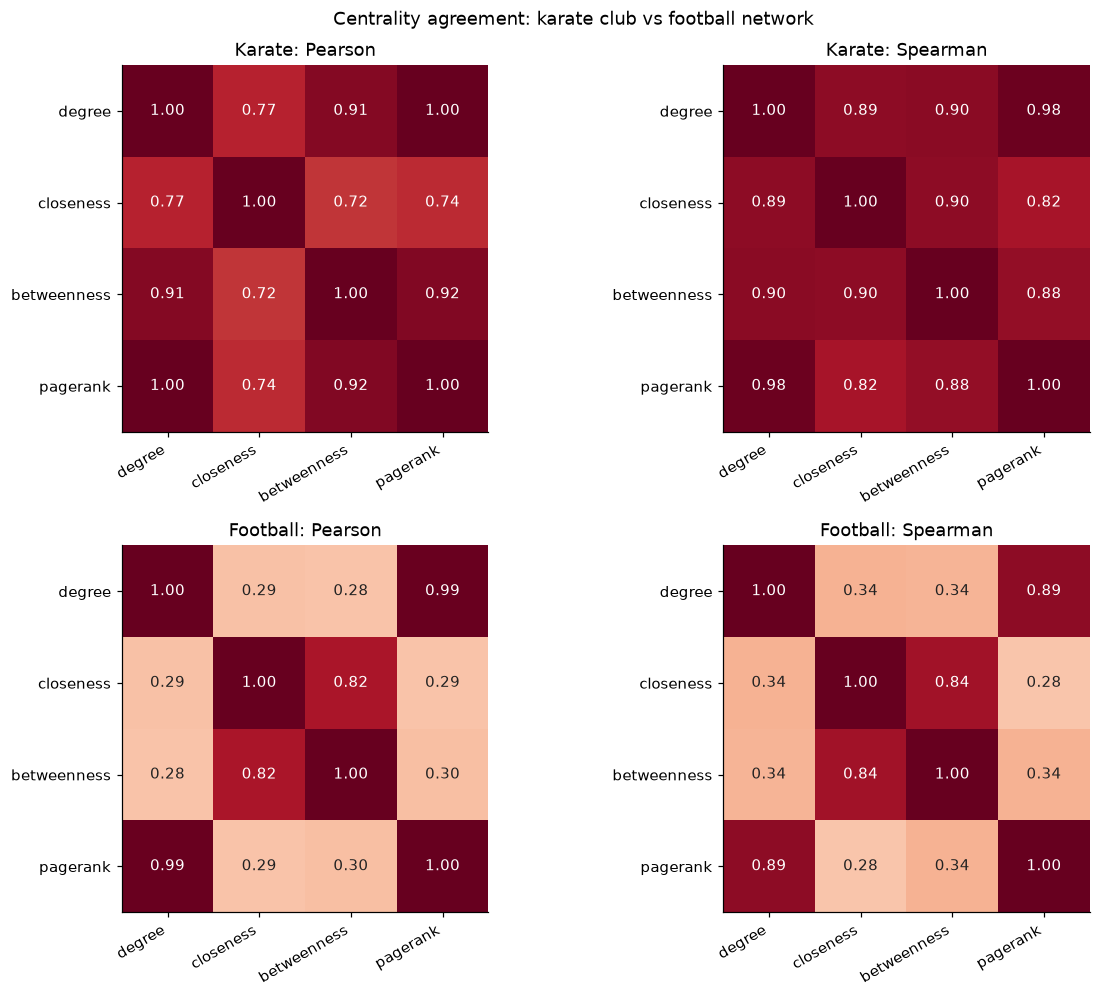

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 9.2))
panels = [(axes[0, 0], pear, "Karate: Pearson"),
          (axes[0, 1], spear, "Karate: Spearman"),
          (axes[1, 0], fb_pear, "Football: Pearson"),
          (axes[1, 1], fb_spear, "Football: Spearman")]
for ax, M, title in panels:
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(M)))
    ax.set_xticklabels(M.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(M)))
    ax.set_yticklabels(M.columns)
    for i in range(len(M)):
        for j in range(len(M)):
            ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(M.iloc[i, j]) > 0.6 else "#222222")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Centrality agreement: karate club vs football network")
fig.tight_layout()
savefig(fig, "08_centrality_comparison.png")
plt.show()

### 13.2 Community structure: does spectral clustering find the conferences?

The number of communities is no longer known in advance, so the spectral method is swept over
$k = 2, \ldots, 12$ and scored two ways:

* **modularity $Q$** — internal quality, with no reference to the truth;
* **adjusted Rand index (ARI)** — agreement with the 12 conferences, where 1 means identical and 0
  means chance.

A method can maximise $Q$ at a different $k$ from the one that best matches the conferences; comparing
the two curves exposes that tension. Because k-means is stochastic, the $k=12$ solution is also run
with ten different seeds to measure stability.

In [43]:
sweep_rows = []
for k in range(2, 13):
    labels_k, comms_k, _ = spectral_partition(FB, k=k)
    sweep_rows.append({"k": k, "modularity Q": modularity(FB, comms_k),
                       "ARI vs conferences": adjusted_rand_index(labels_k, FOOTBALL_CONF),
                       "community sizes": sorted([len(c) for c in comms_k], reverse=True)})
sweep = pd.DataFrame(sweep_rows)
display(sweep.round(4))

best_q_row = sweep.loc[sweep["modularity Q"].idxmax()]
best_ari_row = sweep.loc[sweep["ARI vs conferences"].idxmax()]
print(f"Best Q      : k = {int(best_q_row['k'])}, Q = {best_q_row['modularity Q']:.4f}, "
      f"ARI = {best_q_row['ARI vs conferences']:.4f}")
print(f"Best ARI    : k = {int(best_ari_row['k'])}, Q = {best_ari_row['modularity Q']:.4f}, "
      f"ARI = {best_ari_row['ARI vs conferences']:.4f}")

fb_labels12, fb_comms12, _ = spectral_partition(FB, 12)
fb_q12 = modularity(FB, fb_comms12)
fb_ari12 = adjusted_rand_index(fb_labels12, FOOTBALL_CONF)

stability = []
for seed in range(10):
    lab_s, com_s, _ = spectral_partition(FB, 12, seed=seed)
    stability.append((modularity(FB, com_s), adjusted_rand_index(lab_s, FOOTBALL_CONF)))
stability = np.array(stability)
print(f"\nk = 12 across 10 k-means seeds:")
print(f"  Q   = {stability[:, 0].mean():.4f} +/- {stability[:, 0].std():.4f}")
print(f"  ARI = {stability[:, 1].mean():.4f} +/- {stability[:, 1].std():.4f}")

fb_njw_labels, fb_njw_comms, _ = spectral_partition(FB, 12, include_trivial=True)
print(f"Literal NJW k=12: Q = {modularity(FB, fb_njw_comms):.4f}, "
      f"ARI = {adjusted_rand_index(fb_njw_labels, FOOTBALL_CONF):.4f}")

,k,modularity Q,ARI vs conferences,community sizes
0,2,0.3865,0.1291,"[69, 46]"
1,3,0.5084,0.2674,"[45, 36, 34]"
2,4,0.5260,0.3532,"[40, 26, 25, 24]"
3,5,0.5703,0.4556,"[26, 24, 23, 22, 20]"
4,6,0.5756,0.5628,"[26, 21, 19, 19, 15, 15]"
5,7,0.5817,0.6237,"[21, 20, 19, 15, 14, 14, 12]"
6,8,0.5839,0.6915,"[19, 19, 15, 14, 14, 12, 11, 11]"
7,9,0.5874,0.7404,"[18, 15, 15, 13, 12, 11, 11, 10, 10]"
8,10,0.6025,0.8272,"[15, 14, 14, 12, 11, 10, 10, 10, 10, 9]"
9,11,0.6031,0.8569,"[15, 13, 12, 12, 11, 10, 10, 9, 9, 8, 6]"


Best Q      : k = 11, Q = 0.6031, ARI = 0.8569
Best ARI    : k = 11, Q = 0.6031, ARI = 0.8569

k = 12 across 10 k-means seeds:
  Q   = 0.5833 +/- 0.0059
  ARI = 0.8349 +/- 0.0230
Literal NJW k=12: Q = 0.6005, ARI = 0.8967


saved -> figures\09_football_communities.png


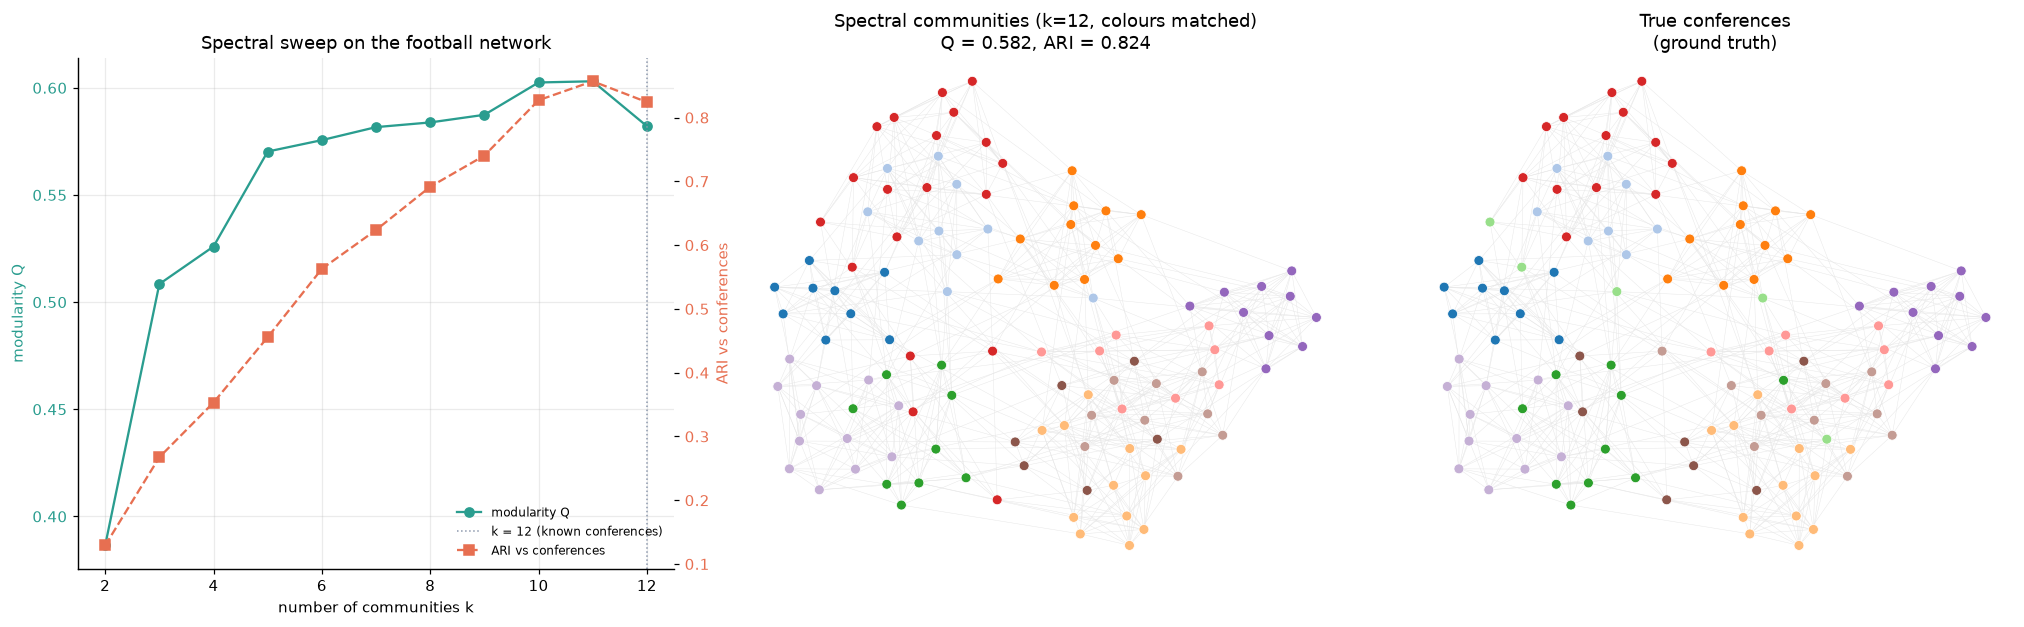

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.8))

ax = axes[0]
ax.plot(sweep["k"], sweep["modularity Q"], "o-", color="#2a9d8f", label="modularity Q")
ax.set_xlabel("number of communities k")
ax.set_ylabel("modularity Q", color="#2a9d8f")
ax.tick_params(axis="y", labelcolor="#2a9d8f")
ax2 = ax.twinx()
ax2.plot(sweep["k"], sweep["ARI vs conferences"], "s--", color="#e76f51",
         label="ARI vs conferences")
ax2.set_ylabel("ARI vs conferences", color="#e76f51")
ax2.tick_params(axis="y", labelcolor="#e76f51")
ax2.grid(False)
ax.set_title("Spectral sweep on the football network")
ax.axvline(12, color="#8d99ae", ls=":", lw=1, label="k = 12 (known conferences)")
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], frameon=False, loc="lower right", fontsize=8)

palette12 = plt.get_cmap("tab20")(np.linspace(0, 1, 20))[:12]

# Match every spectral cluster to its majority conference, so the colours in the two
# right-hand panels are directly comparable.
matched12 = np.empty_like(fb_labels12)
for c in np.unique(fb_labels12):
    members = fb_labels12 == c
    matched12[members] = np.bincount(np.array(FOOTBALL_CONF)[members],
                                     minlength=12).argmax()

for ax, labels, title in [
    (axes[1], matched12,
     f"Spectral communities (k=12, colours matched)\nQ = {fb_q12:.3f}, ARI = {fb_ari12:.3f}"),
    (axes[2], np.array(FOOTBALL_CONF), "True conferences\n(ground truth)"),
]:
    for u, v in FB.edge_list():
        ax.plot([POS_FB[u, 0], POS_FB[v, 0]], [POS_FB[u, 1], POS_FB[v, 1]],
                color="#e6e6e6", lw=0.3, zorder=1)
    ax.scatter(POS_FB[:, 0], POS_FB[:, 1],
               c=[palette12[c] for c in labels], s=42,
               edgecolors="white", linewidths=0.5, zorder=2)
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
savefig(fig, "09_football_communities.png")
plt.show()

### 13.3 Robustness of the larger network

The same attack is repeated, but with $k = 0, 10, \ldots, 60$ removals — up to 52% of the network,
because 5 removals barely register on 115 nodes. Curves are plotted against the **fraction of nodes
removed**, so the two networks can be compared on the same axis.

The two denominators defined in Section 10 are kept: the left panel asks whether the remaining graph
stays connected, the right panel how much of the original graph survives.

In [45]:
fb_steps = list(range(0, 61, 10))
fb_attack_btw = attack(FB, fb_btw, fb_steps)
fb_attack_degree = attack(FB, fb_deg, fb_steps)
fb_attack_pr = attack(FB, fb_pr, fb_steps)

rng = np.random.default_rng(SEED)
fb_random_runs = []
for _ in range(30):
    perm = {u: rng.random() for u in FB.nodes()}
    fb_random_runs.append(attack(FB, perm, fb_steps))
fb_random_curve = np.mean(fb_random_runs, axis=0)

rows = []
for i, k in enumerate(fb_steps):
    rows.append({
        "removed": k,
        "betweenness (remaining)": fb_attack_btw[i][0],
        "betweenness (original)": fb_attack_btw[i][1],
        "degree (remaining)": fb_attack_degree[i][0],
        "degree (original)": fb_attack_degree[i][1],
        "random (remaining)": fb_random_curve[i, 0],
        "random (original)": fb_random_curve[i, 1],
    })
robust_fb = pd.DataFrame(rows)
display(robust_fb.round(3))

print("Football network is still fully connected after removing ...")
for k in (10, 20, 30, 40, 50):
    i = fb_steps.index(k)
    print(f"  {k:2d} nodes ({k / len(FB):.0%}): "
          f"{fb_attack_btw[i][0]:.1%} of remaining, "
          f"{fb_attack_btw[i][1]:.1%} of original")
i = fb_steps.index(60)
print(f"At 60 removed ({60 / len(FB):.0%}):")
print(f"  betweenness: {fb_attack_btw[i][0]:.1%} of remaining, "
      f"{fb_attack_btw[i][1]:.1%} of original")
print(f"  degree     : {fb_attack_degree[i][0]:.1%} of remaining, "
      f"{fb_attack_degree[i][1]:.1%} of original")
print(f"  random     : {fb_random_curve[i, 0]:.1%} of remaining, "
      f"{fb_random_curve[i, 1]:.1%} of original")

,removed,betweenness (remaining),betweenness (original),degree (remaining),degree (original),random (remaining),random (original)
0,0,1.0,1.000,1.000,1.000,1.000,1.000
1,10,1.0,0.913,1.000,0.913,1.000,0.913
2,20,1.0,0.826,1.000,0.826,1.000,0.826
3,30,1.0,0.739,1.000,0.739,1.000,0.739
4,40,1.0,0.652,1.000,0.652,1.000,0.652
5,50,1.0,0.565,1.000,0.565,1.000,0.565
6,60,1.0,0.478,0.964,0.461,0.999,0.478


Football network is still fully connected after removing ...
  10 nodes (9%): 100.0% of remaining, 91.3% of original
  20 nodes (17%): 100.0% of remaining, 82.6% of original
  30 nodes (26%): 100.0% of remaining, 73.9% of original
  40 nodes (35%): 100.0% of remaining, 65.2% of original
  50 nodes (43%): 100.0% of remaining, 56.5% of original
At 60 removed (52%):
  betweenness: 100.0% of remaining, 47.8% of original
  degree     : 96.4% of remaining, 46.1% of original
  random     : 99.9% of remaining, 47.8% of original


saved -> figures\10_cross_dataset_robustness.png


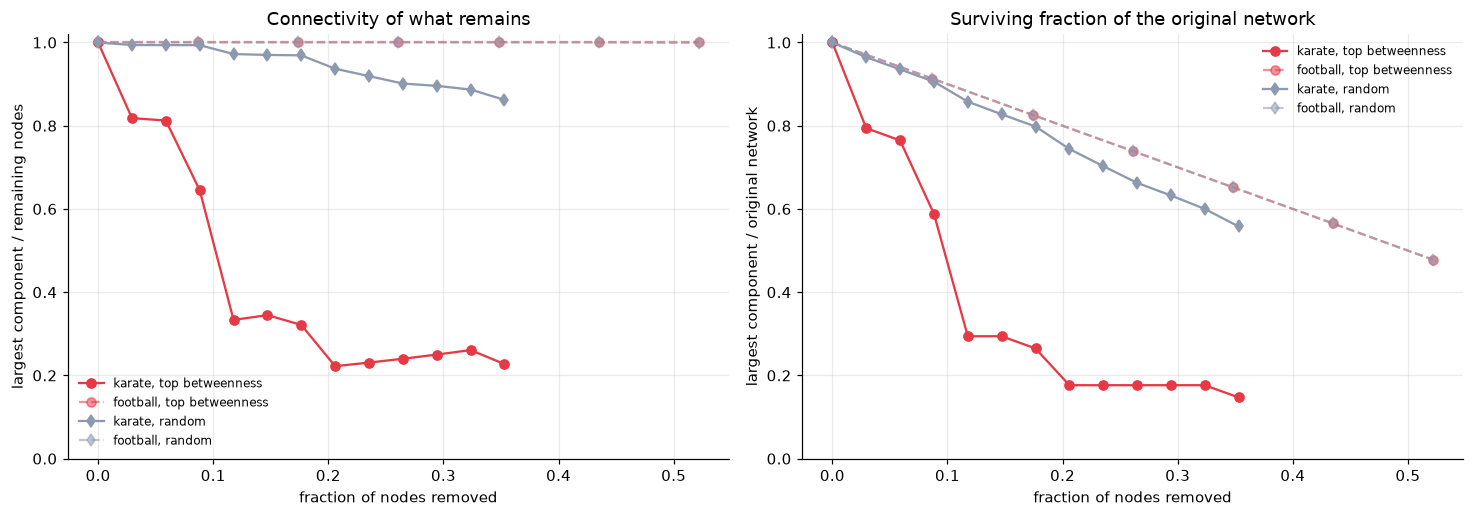

,network,nodes,edges,density,diameter,avg. path,known groups,spectral k,Q,ARI,giant after ~15% removals (remaining)
0,Karate,34,78,0.139,5,2.408,2,2,0.371,1.000,0.345
1,Football,115,613,0.094,4,2.508,12,12,0.582,0.824,1.000


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
x_karate = np.array(steps) / len(G)
x_football = np.array(fb_steps) / len(FB)

for ax, idx, ylabel in [
    (axes[0], 0, "largest component / remaining nodes"),
    (axes[1], 1, "largest component / original network"),
]:
    ax.plot(x_karate, [x[idx] for x in attack_btw], "o-", color="#e63946",
            label="karate, top betweenness")
    ax.plot(x_football, [x[idx] for x in fb_attack_btw], "o--", color="#e63946",
            alpha=0.55, label="football, top betweenness")
    ax.plot(x_karate, random_curve[:, idx], "d-", color="#8d99ae",
            label="karate, random")
    ax.plot(x_football, fb_random_curve[:, idx], "d--", color="#8d99ae",
            alpha=0.55, label="football, random")
    ax.set_xlabel("fraction of nodes removed")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_title("Connectivity of what remains")
axes[1].set_title("Surviving fraction of the original network")
fig.tight_layout()
savefig(fig, "10_cross_dataset_robustness.png")
plt.show()

summary = pd.DataFrame([
    {"network": "Karate", "nodes": len(G), "edges": G.number_of_edges(),
     "density": G.density(), "diameter": diam, "avg. path": avg_path,
     "known groups": 2, "spectral k": 2, "Q": spec_q, "ARI": 1.0,
     "giant after ~15% removals (remaining)": attack_btw[int(round(0.15 * len(G)))][0]},
    {"network": "Football", "nodes": len(FB), "edges": FB.number_of_edges(),
     "density": FB.density(), "diameter": fb_diam, "avg. path": fb_avg_path,
     "known groups": 12, "spectral k": 12, "Q": fb_q12, "ARI": fb_ari12,
     "giant after ~15% removals (remaining)": fb_attack_btw[fb_steps.index(20)][0]},
])
display(summary.round(3))

### 13.4 What the comparison shows

* **Centrality is network-dependent.** On the karate club degree and PageRank are almost the same
  ranking (Pearson 0.98), whereas on the football network degree and closeness/betweenness are only
  weakly correlated (Pearson 0.29/0.28). A team can play many games without being a broker between
  conferences.
* **Spearman is often the more honest summary.** On the skewed karate data, degree–closeness rises
  from 0.77 (Pearson) to 0.90 (Spearman), and closeness–betweenness from 0.72 to 0.90. The metrics
  order the nodes more similarly than the raw-score correlation suggests.
* **Spectral clustering scales and still finds structure.** Modularity rises from $k=2$ and peaks
  around $k=10$–$11$; at the known $k=12$ the partition reaches ARI $\approx 0.83$ against the
  conferences, despite teams playing games outside their conference.
* **The larger network is far more resilient.** Removing 50 of 115 nodes (43%) leaves every remaining
  node connected; the karate club loses a large share of its giant component after only 5 removals
  (15%). Even at 60 removals (52%), the betweenness attack leaves the remaining football graph fully
  connected; the degree attack leaves 96.4% of it connected (46.1% of the original network).

## 14. Putting it together: the influence ranking

A single "importance" score is built by averaging the **ranks** from the four metrics (rank-based
averaging is robust to the very different scales of degree and betweenness). The top ten are extracted
with a **priority queue** (`heapq`, a binary heap, $O(n + k\log n)$) — the DSA structure the brief maps
to "rank important nodes". Community labels are attached so the ranking can be read alongside the
community structure.

In [47]:
def rank01(scores):
    s = pd.Series(scores)
    return s.rank(ascending=False, method="average") / len(s)


composite = pd.DataFrame({
    "node": G.nodes(),
    "degree": [deg[u] for u in G.nodes()],
    "closeness": [clo[u] for u in G.nodes()],
    "betweenness": [btw[u] for u in G.nodes()],
    "pagerank": [pr[u] for u in G.nodes()],
})
composite["influence"] = np.vstack(
    [1 - rank01(composite[c]) for c in ["degree", "closeness", "betweenness", "pagerank"]]
).mean(axis=0)
composite["faction"] = [G.meta[u]["faction"] for u in G.nodes()]
composite["GN community"] = gn_labels
composite = composite.set_index("node")

# max-heap via negated scores -> pop the k most influential nodes
heap = [(-score, u) for u, score in zip(composite.index, composite["influence"])]
heapq.heapify(heap)
top10 = [heapq.heappop(heap)[1] for _ in range(10)]

display(composite.loc[top10].round(4))
print("Top-10 by composite influence:", top10)

,degree,closeness,betweenness,pagerank,influence,faction,GN community
node,,,,,,,
0,0.4848,0.5690,0.4376,0.0970,0.9559,Mr. Hi,0
33,0.5152,0.5500,0.3041,0.1009,0.9485,Officer,3
2,0.3030,0.5593,0.1437,0.0571,0.8971,Mr. Hi,1
32,0.3636,0.5156,0.1452,0.0717,0.8897,Officer,3
31,0.1818,0.5410,0.1383,0.0372,0.8419,Officer,1
1,0.2727,0.4853,0.0539,0.0529,0.8088,Mr. Hi,0
8,0.1515,0.5156,0.0559,0.0298,0.7794,Officer,3
13,0.1515,0.5156,0.0459,0.0295,0.7574,Mr. Hi,0
3,0.1818,0.4648,0.0119,0.0359,0.7169,Mr. Hi,0


Top-10 by composite influence: [0, 33, 2, 32, 31, 1, 8, 13, 3, 23]


## 15. Key findings

The cell below prints the headline numbers produced by this run (so they always match the code).

In [48]:
top_deg = max(deg, key=deg.get)
top_btw = max(btw, key=btw.get)
top_pr = max(pr, key=pr.get)

print("KEY FINDINGS")
print("-" * 74)
print(f"Karate             : {len(G)} nodes, {G.number_of_edges()} edges, "
      f"density {G.density():.3f}, diameter {diam}")
print(f"  most connected   : node {top_deg} (degree {G.degree(top_deg)})")
print(f"  main bridge      : node {top_btw} (betweenness {btw[top_btw]:.3f})")
print(f"  top PageRank     : node {top_pr} (PR = {pr[top_pr]:.4f})")
print(f"  Girvan-Newman    : first split Q = {gn2_q:.4f}, "
      f"ARI = {adjusted_rand_index(gn2_labels, FACTION):.3f}")
print(f"                     max-Q split ({len(gn_comms)} communities) Q = {gn_q:.4f}, "
      f"ARI = {adjusted_rand_index(gn_labels, FACTION):.3f}")
print(f"  Fiedler k=2      : Q = {spec_q:.4f}, "
      f"ARI = {adjusted_rand_index(spec_labels, FACTION):.3f}")
print(f"  literal NJW k=2  : Q = {njw2_q:.4f}, "
      f"ARI = {adjusted_rand_index(njw2_labels, FACTION):.3f}")
print(f"  robustness       : removing 5 top-betweenness nodes leaves "
      f"{attack_btw[5][0]:.0%} of remaining / {attack_btw[5][1]:.0%} of original connected")
print(f"                     removing 5 random nodes leaves "
      f"{random_curve[5, 0]:.0%} of remaining / {random_curve[5, 1]:.0%} of original")
print(f"  composite top-5  : {top10[:5]}")
print()
print(f"Football           : {len(FB)} nodes, {FB.number_of_edges()} edges, "
      f"density {FB.density():.3f}, diameter {fb_diam}, avg. path {fb_avg_path:.2f}")
print(f"  main brokers     : "
      f"{[(FB.meta[u]['name'], round(fb_btw[u], 4)) for u in fb_top_btw[:5]]}")
print(f"  spectral sweep   : best Q at k = {int(best_q_row['k'])} "
      f"(Q = {best_q_row['modularity Q']:.4f})")
print(f"  k=12             : Q = {fb_q12:.4f}, ARI = {fb_ari12:.3f}; "
      f"across 10 seeds ARI = {stability[:, 1].mean():.3f} +/- {stability[:, 1].std():.3f}")
print(f"  robustness       : fully connected after 50/115 removals; "
      f"after 60 removals {fb_attack_btw[6][0]:.0%} of remaining / "
      f"{fb_attack_btw[6][1]:.0%} of original")

KEY FINDINGS
--------------------------------------------------------------------------
Karate             : 34 nodes, 78 edges, density 0.139, diameter 5
  most connected   : node 33 (degree 17)
  main bridge      : node 0 (betweenness 0.438)
  top PageRank     : node 33 (PR = 0.1009)
  Girvan-Newman    : first split Q = 0.3600, ARI = 0.882
                     max-Q split (5 communities) Q = 0.4013, ARI = 0.469
  Fiedler k=2      : Q = 0.3715, ARI = 1.000
  literal NJW k=2  : Q = 0.3600, ARI = 0.882
  robustness       : removing 5 top-betweenness nodes leaves 34% of remaining / 29% of original connected
                     removing 5 random nodes leaves 97% of remaining / 83% of original
  composite top-5  : [0, 33, 2, 32, 31]

Football           : 115 nodes, 613 edges, density 0.094, diameter 4, avg. path 2.51
  main brokers     : [('NotreDame', 0.0335), ('BrighamYoung', 0.0325), ('Navy', 0.0292), ('LouisianaTech', 0.0288), ('CentralMichigan', 0.0252)]
  spectral sweep   : best Q a

In [49]:
rank_table.to_csv(
    "../results/centrality_analysis/karate_centrality.csv",
    index=False
)

print("Karate Club centrality results exported successfully!")

Karate Club centrality results exported successfully!


In [50]:
import pandas as pd

football_centrality = pd.DataFrame({
    "Team": [FB.meta[u]["name"] for u in FB.nodes()],
    "Node_ID": list(FB.nodes()),
    "Degree": [FB.degree(u) for u in FB.nodes()],
    "Betweenness_Centrality": [fb_btw[u] for u in FB.nodes()]
})

football_centrality = football_centrality.sort_values(
    by="Betweenness_Centrality",
    ascending=False
)

football_centrality.to_csv(
    "../results/centrality_analysis/football_centrality.csv",
    index=False
)

print("Football centrality results exported successfully!")

Football centrality results exported successfully!


## 16. Complexity summary

| Step | Algorithm / structure | Time | Space |
|---|---|---|---|
| Build graph | adjacency list (hash maps) | $O(V+E)$ | $O(V+E)$ |
| BFS / DFS | queue / stack | $O(V+E)$ | $O(V)$ |
| Components | repeated BFS | $O(V+E)$ | $O(V)$ |
| Components (dynamic) | Union-Find, path compression | $O(E\,\alpha(V))$ | $O(V)$ |
| Degree centrality | counting | $O(V+E)$ | $O(V)$ |
| Closeness centrality | BFS from every node | $O(V(V+E))$ | $O(V)$ |
| Betweenness centrality | Brandes | $O(VE)$ unweighted | $O(V+E)$ |
| PageRank | power iteration, $k$ rounds | $O(k(V+E))$ | $O(V+E)$ |
| Girvan–Newman | edge betweenness $\times\,m$ removals | $O(m^2V)$ | $O(V+E)$ |
| Spectral clustering | dense eigendecomposition | $O(V^3)$ | $O(V^2)$ |
| k-means++ | Lloyd iterations | $O(nkdi)$ | $O(nk)$ |
| Attack simulation | repeated BFS | $O(k(V+E))$ | $O(V+E)$ |

The karate run finishes in milliseconds; the football network (115 nodes, 613 edges) still finishes
every experiment in seconds on a CPU. The point of the table is what happens when the same code is
pointed at a network with millions of edges: betweenness and Girvan–Newman become the bottlenecks,
while BFS, PageRank and spectral methods remain practical with the right linear-algebra backend.

## 17. Experimental discussion

### 17.1 Research question

The project asks whether a small set of mathematically distinct tools — connectivity, centrality,
modularity and spectral embedding — can (i) recover the known group structure of a social network,
(ii) identify the nodes whose removal matters, and (iii) produce conclusions that survive being moved
to a different, larger network. The football experiment is the test of the third claim.

### 17.2 Methodology

Every algorithm is implemented from scratch on an adjacency-list graph; NetworkX is used only as an
independent referee. Centrality is measured four ways, and their agreement is quantified with Pearson,
Spearman and top-10 overlap. Communities are found both divisively (Girvan–Newman) and spectrally
(Fiedler variant and literal NJW), and evaluated with modularity (internal) and ARI (external, against
known labels). Robustness is measured by removing nodes in four orders and tracking the giant
component with two denominators. The second dataset uses exactly the same code paths.

### 17.3 Results

On the karate club, degree, closeness, betweenness and PageRank agree strongly but not perfectly
(Pearson 0.72–1.00). Spearman correlations are systematically higher for the skewed pairs (for example
degree–closeness 0.77 → 0.90), which shows that the metrics rank nodes more similarly than raw
correlations imply. Girvan–Newman's first cut reproduces the historical split (ARI 0.88); the Fiedler
variant of spectral clustering reproduces it exactly (ARI 1.00, $Q=0.371$), while the literal NJW
variant with the trivial eigenvector gives ARI 0.88. Removing the five highest-betweenness nodes leaves
only 34.5% of the remaining nodes connected (29.4% of the original), compared with 97.0% under random
removal.

On the football network, the same pipeline finds Notre Dame, Brigham Young and Navy as the leading
brokers, recovers the conference structure at ARI $\approx 0.83$ for $k=12$, and shows much weaker
degree–closeness agreement (Pearson 0.29). The network is also far more resilient: after removing 50 of
115 nodes it is still fully connected. Even at 60 removals (52%), the betweenness attack leaves the
remaining graph fully connected; the degree attack leaves 96.4% of what remains (46.1% of the
original).

### 17.4 What the results mean

The comparison separates **universal** from **network-specific** behaviour. Connectivity, the
existence of hubs, and the presence of community structure appear in both networks. The *identity* of
the important nodes and the *strength* of agreement between centrality definitions do not: they depend
on density, degree distribution and the number of cross-group edges. Likewise, resilience is not a
fixed property of "social networks" — the football graph is markedly harder to fragment than the
karate club because it is denser and has no single cut vertex.

This is exactly why the report reports both denominators. "34.5% of remaining nodes" sounds less
alarming than "the network lost two-thirds of its members", but both are true; the first describes the
fragmenting process, the second the damage.

### 17.5 Limitations

* **Stochastic clustering.** k-means can reach different local optima. At $k=12$ on football, ten seeds
  give ARI $0.83 \pm 0.02$; a single run should not be reported as *the* answer.
* **Modularity has a resolution limit.** It tends to merge small communities, which is one reason the
  best-$Q$ $k$ (10–11) differs from the known 12 conferences.
* **Conference labels are not a perfect partition.** Teams play games outside their conference, so ARI
  cannot reach 1 even with a perfect algorithm.
* **Karate ground truth is historically contested.** The two-faction label is a simplification; the
  max-$Q$ solution finds five sub-communities that are also meaningful.
* **Only node removal is tested.** Real failures are often edge removals (a cancelled route, a broken
  link); the same experiment can be repeated with edge attacks.
* **Static, unweighted, undirected graphs.** The football games are treated as unweighted edges, and
  time (which game was played when) is ignored.
* **Small scale.** 115 nodes is larger than 34 but still tiny; exact betweenness and Girvan–Newman need
  approximation on real platforms.

### 17.6 Future work

1. Replace Girvan–Newman with Louvain/Leiden and compare modularity and stability at scale.
2. Estimate betweenness from a sample of sources and quantify the approximation error.
3. Add edge-removal and cascading-failure models.
4. Use weighted or temporal edges, and directed graphs (citation, follower, transaction networks).
5. Replace spectral embedding + k-means with node2vec/GraphSAGE and compare ARI on the same splits.
6. Test whether the ranking of brokers predicts an external outcome (club split, game results,
   conference championships) rather than only matching a label.

## 18. Conclusion

This project turned social networks into mathematical objects and interrogated them with classical
algorithms:

* **Graph representation** (adjacency list + hash maps) gives $O(1)$ neighbour access and $O(V+E)$
  memory.
* **BFS / DFS / Union-Find** answer connectivity questions and produce the shortest-path distances that
  closeness and betweenness depend on.
* **Degree, closeness, betweenness and PageRank** identify different kinds of importance. On the karate
  club the broker nodes (0 and 33) are not the same as the largest communities; on football the
  rankings diverge even more, which is why correlation analysis is part of the result rather than an
  afterthought.
* **Girvan–Newman's first cut** recovers the historical Mr. Hi / Officer split almost exactly
  (ARI 0.88), and the **Fiedler variant of spectral clustering** recovers it perfectly (ARI 1.00).
  The literal NJW variant, which includes the trivial eigenvector, reaches ARI 0.88 at $k=2$ — a
  concrete demonstration that an apparently minor implementation choice changes the answer.
* **Targeted removal** of the top brokers fragments the karate club far faster than random removal,
  while the larger football network survives the loss of nearly half its nodes. Resilience is a
  property of the network, not a universal law.
* **Repeating the pipeline on a second network** is what turns a case study into evidence: the
  algorithms generalise, but the rankings and the robustness do not.

The same pipeline (represent → traverse → rank → cluster → stress-test → compare) applies directly to
social platforms, communication networks, supply chains, and fraud detection.

## 19. References

1. W. W. Zachary, *An information flow model for conflict and fission in small groups*, Journal of
   Anthropological Research, 1977.
2. U. Brandes, *A faster algorithm for betweenness centrality*, Journal of Mathematical Sociology, 2001.
3. L. Page, S. Brin, R. Motwani, T. Winograd, *The PageRank citation ranking*, Stanford, 1998.
4. M. E. J. Newman, M. Girvan, *Finding and evaluating community structure in networks*, Phys. Rev. E, 2004.
5. M. Girvan, M. E. J. Newman, *Community structure in social and biological networks*, PNAS, 2002.
   (Source of the American college football network.)
6. A. Y. Ng, M. I. Jordan, Y. Weiss, *On spectral clustering: analysis and an algorithm*, NeurIPS, 2001.
7. S. Fortunato, *Community detection in graphs*, Physics Reports, 2010.